<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/03_forecastability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 03 · Forecastability

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

Some series are easy to forecast and some are close to impossible, whatever model you use. This notebook measures
how predictable each target series is, and at which horizons, before any model runs. It uses a panel of measures,
each looking at predictability from a different angle: how variable the series is, how long it remembers its
level, how much a linear model can explain, whether it behaves like a random walk, whether the order of its values
matters, how regular it is (entropy), how much of it is slow and smooth, and whether it has long memory or chaotic
dynamics. The set of measures follows a recent textbook treatment of forecastability (see References).

For each measure the notebook explains the question it asks, how to read the number and when it is the right tool,
and it sets every result next to the same measure computed on noise. It then combines the measures into one
profile and one plain-language story per series, and ends with an *expected difficulty* ranking that is written
down before any zero-shot results exist.

Why does this matter? A model's error means little until you know how hard the series is. A price that behaves
like a random walk cannot be forecast much better than "no change", whatever the model; a seasonal temperature
series can. Measuring forecastability sets realistic expectations, lets the chapter group its results by
difficulty (for example, "foundation models gain most on the predictable, structured series"), and provides
features for the chapter's guide to choosing a model.

The targets are D1 (temperature), D3 (five metals), B1 (WTI) and B2 (five yields), twelve series in all. D2 and D4
share the targets of D1 and D3. What their covariates can add was studied in Notebook 02 and is measured directly,
as the gain in accuracy, in the forecasting notebooks. Every number quoted in the text comes from the data snapshot
of 30 September 2026 (downloaded on 1 November 2026); a later download will move the numbers slightly.

**What you will learn**

- why forecastability is measured before any model runs, and what such measures can and cannot tell you
- two complementary views of predictability: how well the *level* can be forecast, and how much structure is left
  once the persistence that a naive forecast already captures is removed
- for about fifteen measures: the question each one asks, its maths, how to read the number and when to use it
- how to read every measure against a noise reference (the same values in random order), and against a simulated
  artefact (monthly averaging) that imitates structure
- how to combine the measures into one profile per series, and which measures suit which kind of data
- how to turn the measures into an explicit, testable expectation for the zero-shot experiments

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 (Google Colab runs 3.13) |
| Packages | [`requirements-dataprep.txt`](requirements-dataprep.txt) (pinned versions); on Colab the setup cell adds the few that Colab lacks ([`requirements-colab.txt`](requirements-colab.txt)) |
| Hardware | CPU only (Colab free tier is enough) |
| Network | none: reads the frozen datasets in `input_timeseries/` |
| Run time | about 3 minutes on 4 CPU cores (Colab's free tier has 2: allow up to twice as long) |
| Peak memory | 1.4 GB (kernel peak) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the
  packages Colab does not have (about a minute). If it says it is restarting the session, wait, then choose
  *Runtime > Run all* again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path.
- **Your own computer (Cursor, VS Code or Jupyter):** create an environment with
  `uv venv .venv-dataprep -p 3.12 && uv pip install -p .venv-dataprep -r requirements-dataprep.txt` (or
  `python -m venv .venv-dataprep` and `pip install -r ...`), open this folder, choose that environment's kernel and run
  all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/v3  |  Python 3.12.3  |  Colab: False


In [2]:
from pathlib import Path

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
HADCET_PAGE = "https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html"
HADCET_FILE = "meantemp_daily_totals.txt"
CPC_NAO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.nao.cdas.z500.19500101_current.csv"
CPC_AO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.ao.cdas.z1000.19500101_current.csv"
PINK_SHEET_PAGE = "https://www.worldbank.org/en/research/commodity-markets"
# direct link to the same workbook (checked 1 Nov 2026: "Updated on October 02, 2026"); used if the page is unreachable
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/"
                  "CMO-Historical-Data-Monthly.xlsx")

N_DAILY = 10_000            # most recent observations kept for daily data
MONTHLY_START = "1982-01-01"  # first month of the Cleveland Fed real-rate series
HORIZONS = {"daily": [7, 14, 30, 60, 90], "monthly": [3, 6, 9, 12, 24]}
ROLLING_WINDOWS = {"daily": {7: 5, 14: 5, 30: 5, 60: 5, 90: 5},
                   "monthly": {3: 3, 6: 3, 9: 3, 12: 3, 24: 1}}
HADCET_LAT = 52.5           # latitude used for day length (degrees north)

METALS = {  # column: (World Bank Pink Sheet column, FRED id of the IMF series used as a cross-check, description)
    "copper": ("Copper", "PCOPPUSDM", "Copper (LME), grade A cathodes, USD per metric ton"),
    "aluminium": ("Aluminum", "PALUMUSDM", "Aluminium (LME), primary ingots 99.7 %, USD per metric ton"),
    "nickel": ("Nickel", "PNICKUSDM", "Nickel (LME), cathodes 99.8 %, USD per metric ton"),
    "zinc": ("Zinc", "PZINCUSDM", "Zinc (LME), high grade 99.95 %, USD per metric ton"),
    "lead": ("Lead", "PLEADUSDM", "Lead (LME), refined 99.97 %, USD per metric ton"),
}
DRIVERS = {  # column: (FRED id, fallback FRED id, description)
    "global_activity": ("IGREA", None, "Kilian index of global real economic activity (% deviation from trend)"),
    "usd": ("NNUSBIS", "TWEXBGSMTH", "US dollar nominal effective exchange rate, BIS narrow index (2020 = 100)"),
    "real_rate_10y": ("REAINTRATREARAT10Y", "DFII10", "US 10-year real interest rate, Cleveland Fed (%)"),
}
TREASURY = {"y3m": "DGS3MO", "y1": "DGS1", "y2": "DGS2", "y5": "DGS5", "y10": "DGS10"}
WTI = "DCOILWTICO"

DATASETS = {
    "D1": {"name": "Central England Temperature, daily mean", "kind": "U", "grain": "daily",
           "targets": ["temp"], "covariates": []},
    "D2": {"name": "Central England Temperature + covariates", "kind": "U+X", "grain": "daily",
           "targets": ["temp"],
           "known_future": ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2",
                            "fourier_sin_3", "fourier_cos_3", "daylength_h"],
           "past_only": ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8", "nao", "ao"]},
    "D3": {"name": "Base-metal prices, monthly", "kind": "MV", "grain": "monthly",
           "targets": list(METALS), "covariates": []},
    "D4": {"name": "Base metals + global drivers", "kind": "MV+X", "grain": "monthly",
           "targets": list(METALS), "known_future": [], "past_only": list(DRIVERS)},
    "B1": {"name": "WTI crude oil, daily spot", "kind": "U", "grain": "trading day",
           "targets": ["wti"], "covariates": []},
    "B2": {"name": "US Treasury yield curve, daily", "kind": "MV", "grain": "trading day",
           "targets": list(TREASURY), "covariates": []},
}


def find_root(start=None):
    """The chapter folder: the one that holds src/ch03_dataprep and data/."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "ch03_dataprep").is_dir() and (p / "data").is_dir():
            return p
    raise FileNotFoundError("Run the notebook from inside the Chapter 3 folder.")


def grain_key(dataset_id):
    """'daily' for daily and trading-day data, 'monthly' otherwise."""
    return "monthly" if DATASETS[dataset_id]["grain"] == "monthly" else "daily"

In [3]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ch03_dataprep.plotting import INK, INK_2, SEQUENTIAL, SERIES as COLORS, SURFACE, set_style

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)

SNAP = {name: pd.read_csv(INPUT / f"{name}.csv", index_col=0, parse_dates=True)
        for name in ["D1", "D3", "B1", "B2"]}
SEASON = {"daily": 365, "monthly": 12, "trading day": 5}
TARGETS = [("D1", "temp")] + [("D3", m) for m in METALS] + [("B1", "wti")] + [("B2", c) for c in TREASURY]


def structure_view(d, c):
    """The stationary form used for the structure measures, and its name."""
    s = SNAP[d][c].dropna()
    if d == "D1":
        return s, "level"
    if d == "D3":
        return np.log(s).diff().dropna(), "log change"
    return s.diff().dropna(), "change"    # WTI (negative in April 2020, so no logs) and yields


def shuffled(z, k=0):
    """The same values in random order (shuffle number k): the noise reference for every structure measure."""
    return np.random.default_rng(2026 + k).permutation(np.asarray(z, float))


for d, c in TARGETS:
    s = SNAP[d][c].dropna()
    print(f"{d}:{c:10s} {len(s):6,} points, structure measures on: {structure_view(d, c)[1]}")

D1:temp       10,000 points, structure measures on: level
D3:copper        535 points, structure measures on: log change
D3:aluminium     535 points, structure measures on: log change
D3:nickel        535 points, structure measures on: log change
D3:zinc          535 points, structure measures on: log change
D3:lead          535 points, structure measures on: log change
B1:wti         9,513 points, structure measures on: change
B2:y3m        10,000 points, structure measures on: change
B2:y1         10,000 points, structure measures on: change
B2:y2         10,000 points, structure measures on: change
B2:y5         10,000 points, structure measures on: change
B2:y10        10,000 points, structure measures on: change


## Why test forecastability before forecasting?

#### What forecastability is

The forecastability of a series at horizon $H$ is how much of its future value can be predicted from what is known
when the forecast is made. A classic way to make this precise is the share of the variance of $y_{t+H}$ that the
best possible forecast $\hat y^{\ast}_ {t+H}$ explains:

$$R^2_H = 1 - \frac{\operatorname{Var}\big(y_{t+H} - \hat y^{\ast}_ {t+H}\big)}{\operatorname{Var}(y_{t+H})}. \tag{0}$$

Nobody knows the best possible forecast, so no single number gives $R^2_H$. Each measure in this notebook
approaches it from a different side. Three consequences of the definition guide everything that follows.

- Forecastability belongs to the **series**, the **horizon** and the **information** used, not to a model. A better
  model gets closer to the limit; it cannot raise it.
- It usually **falls as the horizon grows**, so we measure it at each forecast horizon of the chapter.
- It **rises with useful information.** A covariate that carries information about the future raises the limit.
  Notebook 02 asked which covariates might, and the forecasting notebooks measure whether they do.

#### Why check it before running any model?

There are five reasons, and each is used later in the chapter.

1. **An error needs a reference.** A mean absolute error of 1.5 °C, or a MASE of 0.95, means nothing on its own.
   The same error can be excellent on a hard series and poor on an easy one, and forecastability tells you which.
2. **It names the baseline a model has to beat.** For a random walk, "no change" is the best forecast there is; for
   a strongly seasonal series, the value on the same day last year is a hard baseline at long horizons. Scaled
   errors such as MASE divide by the error of the naive forecast, so knowing how good the naive forecast is tells
   you what a MASE of 1 means.
3. **It flags results that are too good.** On a series with almost no order beyond persistence, a large win over
   the naive forecast more likely comes from leakage, a lucky test window or test data already seen in
   pre-training than from skill. The last risk is specific to foundation models, which are pre-trained on large
   public collections of series.
4. **It explains results instead of averaging them away.** A model's average score over twelve series hides
   whether it gains where there is structure to find. Grouping the results by forecastability shows where
   foundation models add value and where nothing can.
5. **It guides the zero-shot set-up.** It tells us how much context is worth giving a model (memory measures), at
   which horizons skill should vanish (horizon measures) and which baseline to report next to every model. In
   zero-shot forecasting nothing is fitted to our series, so these measurements are the main thing we know in
   advance about what each model faces.

#### What the measures cannot tell you

They read the past. Whether something can be forecast depends on how well we understand the factors that drive
it, how much data there is, and whether the forecast itself changes the outcome. The measures here speak only to
the data: how much regular pattern the history holds. A policy change, a new market regime or a pandemic is not in
the history, so every number here is an expectation to check against out-of-sample results, not a guarantee.

#### Why so many measures?

No single number captures forecastability. Each measure asks one narrow question under its own assumptions, and
each can be fooled in its own way: by a trend, a seasonal cycle, monthly averaging or values stuck at zero. So the
notebook uses them as a panel. Where measures built on different ideas agree, the conclusion is solid; where they
disagree, the disagreement usually points to an artefact worth understanding. Section 7 puts them together.

### A map of the measures

| Question | Measure | Section | How to read it | Most useful when |
|---|---|---|---|---|
| Is the series smooth, erratic or intermittent? | CoV, ADI–CV² classes | 1 | *intermittent* or *lumpy* series need special methods | counts or sales with many zeros |
| How much of today's level survives $H$ steps? | autocorrelation at $H$ | 2 | near 1: the level carries over | always, as the first look |
| How good are the simplest forecasts already? | naive and seasonal-naive skill (NSE) | 2 | the bar any model must clear | always; it names the baseline |
| Random walk, mean reversion or momentum? | variance ratio | 2 | 1 random walk, below 1 mean reversion, above 1 momentum | prices, rates, any series with a unit root |
| Is there order beyond the mix of values? | shuffle score $\eta$ | 2 | the share of error that the order removes | always; on changes for trending series |
| How much of the next value can a linear model anticipate? | AR variance explained | 3 | upper bound for one-step linear skill | stationary series and changes |
| How regular is the series? | spectral entropy and $\Omega$; permutation, sample and SVD entropy | 4 | lower entropy than noise: repeated patterns | long stationary series |
| Does the structure persist across time scales? | multiscale entropy | 4 | flat or rising with scale: structure at many scales | long series (thousands of points) |
| Noise, correlated noise or chaos? | complexity–entropy plane | 4 | distance from the white-noise corner | physical systems, possibly chaotic |
| How much variance is slow and smooth? | EMD and VMD low-frequency share | 5 | slow share above noise: components that extrapolate | cycles at known periods |
| Does the past matter over long spans? | DFA exponent $\alpha$ | 6 | 0.5 short memory, between 0.5 and 1 long memory | choosing the context length |
| How far ahead can any forecast be useful? | Lyapunov exponent and $1/\lambda$ | 6 | only if clearly above its shuffled value | low-noise deterministic systems |

## Two views of predictability

The forecasting notebooks score forecasts of the **level** $y_{T+H}$. For a random walk, "tomorrow equals today" is
already a good level forecast, so measures based on the level call a random walk highly predictable. That is true
but unhelpful: whatever a model can add beyond the naive forecast lives in the **changes**. We therefore look at
every series in two ways.

- **View A, the level (horizon measures):** autocorrelation at the horizon, naive and seasonal-naive skill, the
  variance ratio and the shuffle score, all as functions of $H$.
- **View B, the structure (shape measures):** variance explained by an AR model, entropies, complexity,
  decomposition and long memory, computed on a stationary form of each series. That form is the temperature as it
  is (it is stationary around its annual cycle, as Notebook 01 found), log changes for metal prices, and first
  changes for WTI (it was negative in April 2020, so logs are undefined) and for the yields.

A series that is easy in view A and hard in view B, as a random walk is, will make every model look good and no
model look better than the naive forecast. Spotting that combination is the most important thing this notebook
can do.

#### A noise reference for every number

Most structure measures have no natural scale. Is a sample entropy of 1.9 high or low? Shuffling a series keeps
every value but destroys their order, so the same measure on a shuffled copy shows what the number looks like when
there is no structure at all, for the same distribution and the same length. Every view B measure is shown next to
its shuffled value, and only the difference counts. This matters most for short series, where estimation noise
alone can look like structure.

## 1 · Variability: coefficient of variation and the ADI–CV² classes

Is the series smooth, erratic, intermittent or lumpy? These four classes decide which family of methods is even
appropriate, so forecastability studies usually start here.

The coefficient of variation (CoV) compares the typical spread of the values with their typical size,
$\mathrm{CoV} = s/\bar y$. The demand classes add two more numbers. The average inter-demand interval (ADI) says
how often a non-zero value occurs,

$$\mathrm{ADI} = \frac{n}{n_{>0}},$$

the number of observations per non-zero observation, and $\mathrm{CV}^2$, the squared CoV of the non-zero values,
says how much those values vary in size. The usual cut-offs are $\mathrm{ADI} = 1.32$ and $\mathrm{CV}^2 = 0.49$:

- *smooth* (ADI < 1.32, CV² < 0.49): regular values; standard methods apply;
- *erratic* (ADI < 1.32, CV² ≥ 0.49): regular timing, very variable sizes;
- *intermittent* (ADI ≥ 1.32, CV² < 0.49): many zeros, stable sizes; methods such as Croston's are built for this;
- *lumpy* (ADI ≥ 1.32, CV² ≥ 0.49): many zeros and variable sizes, the hardest case.

These classes matter for demand, sales, spare parts or insurance claims, where many periods have no value at all.
Keep two limits in mind. The CoV only makes sense for positive values on a ratio scale (prices, counts, volumes);
for temperature in °C the zero point is arbitrary, and the same temperatures written in kelvin would give a
different CoV. And on a level with a trend or regime shifts, the CoV measures those shifts as much as the noise.

In [4]:
import warnings

import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf


def adi_cv2(x):
    """Syntetos-Boylan demand classes: ADI = n / n_nonzero and CV^2 of non-zero values.

    Cut-offs ADI = 1.32 and CV^2 = 0.49 (Syntetos, Boylan & Croston, 2005).
    Only defined for non-negative series; returns None otherwise.
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if np.any(x < 0):
        return None
    nz = x[x > 0]
    adi = len(x) / len(nz)
    cv2 = (nz.std(ddof=1) / nz.mean()) ** 2
    cls = ("smooth" if adi < 1.32 and cv2 < 0.49 else "erratic" if adi < 1.32
           else "intermittent" if cv2 < 0.49 else "lumpy")
    return {"adi": adi, "cv2": cv2, "class": cls}


def acf_at(x, lags):
    """Autocorrelation at the given lags."""
    x = np.asarray(x, float)
    r = acf(x[~np.isnan(x)], nlags=max(lags), fft=True)
    return {lag: float(r[lag]) for lag in lags}


def ar_variance_explained(x, max_lag):
    """1 - sigma_e^2 / sigma_y^2 of the AIC-best AR(p), p <= max_lag (OLS fit)."""
    from statsmodels.tsa.ar_model import ar_select_order

    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sel = ar_select_order(x, maxlag=max_lag, ic="aic", trend="c")
        res = sel.model.fit()
    p = len(sel.ar_lags or [])
    return {"ar_order": p, "var_explained": float(1 - np.var(res.resid) / np.var(x[p:]))}


def naive_skill(x, horizon, season=None):
    """Nash-Sutcliffe efficiency of the naive (or seasonal-naive) H-step forecast.

    NSE = 1 - sum (y_{t+H} - yhat)^2 / sum (y_{t+H} - mean(y))^2, with
    yhat = y_t (naive) or y_{t+H-m*ceil(H/m)} (seasonal naive, period m).
    NSE = 1 is perfect, 0 is no better than the mean, < 0 is worse than the mean.
    """
    x = np.asarray(x, float)
    back = horizon if season is None else season * int(np.ceil(horizon / season))
    pred, obs = x[: len(x) - back], x[back:]
    ok = ~np.isnan(pred) & ~np.isnan(obs)
    return float(1 - np.sum((obs[ok] - pred[ok]) ** 2) / np.sum((obs[ok] - obs[ok].mean()) ** 2))


def variance_ratio(x, k):
    """Lo-MacKinlay variance ratio VR(k) with the heteroskedasticity-robust test.

    VR(k) = Var(y_{t+k} - y_t) / (k Var(y_{t+1} - y_t)). About 1 for a random
    walk, below 1 for mean reversion, above 1 for trending (momentum).
    """
    from arch.unitroot import VarianceRatio

    x = np.asarray(x, float)
    vr = VarianceRatio(x[~np.isnan(x)], lags=k, robust=True)
    return {"vr": float(vr.vr), "p": float(vr.pvalue)}


def kaboudan_eta(x, horizon, max_lag, n_shuffles=5, seed=0):
    """Kaboudan (1999) shuffle score at horizon H: eta = 1 - SSE(original) / SSE(shuffled).

    A direct H-step linear model, y_{t+H} = c + sum_{j<p} b_j y_{t-j} + e, with
    p chosen by AIC (at most max_lag), is fitted to the whole series, and the
    same model is fitted to random permutations of it (the shuffled SSE is
    averaged over n_shuffles permutations). As in Kaboudan's definition, both
    fits use the whole series, so the original and the shuffled copies hold
    exactly the same values and differ only in their order. (Scoring the
    original on its last stretch and the shuffles on a random mix would also
    compare a calm or volatile final period with the average, which is not
    order.) Shuffling destroys temporal order but keeps the distribution, so
    eta near 0 means no order this model class can exploit at horizon H, and
    eta near 1 means most of the error disappears thanks to order. Kaboudan
    used genetic programming; a linear model keeps the idea simple and fast.
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    p = max(1, ar_variance_explained(x, max_lag)["ar_order"])

    def sse(z):
        n = len(z) - horizon - p + 1
        X = np.column_stack([np.ones(n)] + [z[p - 1 - j: p - 1 - j + n] for j in range(p)])
        y = z[p - 1 + horizon: p - 1 + horizon + n]
        beta = np.linalg.lstsq(X, y, rcond=None)[0]
        return float(np.sum((y - X @ beta) ** 2))

    rng = np.random.default_rng(seed)
    sse_shuffled = np.mean([sse(rng.permutation(x)) for _ in range(n_shuffles)])
    return {"eta": 1 - sse(x) / sse_shuffled, "ar_order": p}

In [5]:
rows = []
for d, c in TARGETS:
    s = SNAP[d][c].dropna()
    cls = adi_cv2(s)
    rows.append({"series": f"{d}:{c}", "cov": s.std() / s.mean(),
                 "adi": cls["adi"] if cls else np.nan, "cv2": cls["cv2"] if cls else np.nan,
                 "class": cls["class"] if cls else "n/a (negative values)"})
variability = pd.DataFrame(rows).set_index("series")
y3m = SNAP["B2"]["y3m"].dropna()
print(f"3-month yield: {(y3m < 0.25).mean():.0%} of days below 0.25 %, {(y3m > 5).mean():.0%} of days above 5 %")
variability.style.format(precision=3, na_rep="–").set_caption(
    "A dash (–) means not defined: ADI and CV² need non-negative values, and daily temperature (°C) "
    "and WTI (-36.98 $/bbl on 20 April 2020) go below zero.")

3-month yield: 23% of days below 0.25 %, 31% of days above 5 %


,cov,adi,cv2,class
series,,,,
D1:temp,0.490,–,–,n/a (negative values)
D3:copper,0.658,1.000,0.433,smooth
D3:aluminium,0.297,1.000,0.088,smooth
D3:nickel,0.605,1.000,0.366,smooth
D3:zinc,0.507,1.000,0.257,smooth
D3:lead,0.627,1.000,0.393,smooth
B1:wti,0.597,–,–,n/a (negative values)
B2:y3m,0.785,1.002,0.613,erratic
B2:y1,0.740,1.000,0.548,erratic


**What this tells us.** Almost no level is ever exactly zero (only the 3-month yield, on 0.2 % of days), so the ADI
is 1 everywhere and every series with positive values is *smooth* or *erratic*. The 3-month and 1-year yields come
out *erratic* (CV² 0.61 and 0.55), but not because they jump around from day to day: the 3-month yield spent 23 %
of the days below 0.25 % and 31 % above 5 %, so its level moves between regimes. Temperature and WTI have negative
values, so the classes are undefined for them, and temperature's CoV of 0.49 has no meaning, because it would
change if the same temperatures were written in kelvin.

This section rules a problem out rather than finding one. Intermittency is not the difficulty in these data;
persistence is, and Section 2 measures it.

## 2 · View A: forecastability by horizon

For each forecast horizon $H$ we ask four questions. How much of today's level is still there $H$ steps later? How
good are the simplest forecasts already? Does the series behave like a random walk, revert to a mean, or keep
moving in the same direction? And does the order of the values carry any information a model could use?

#### Autocorrelation at the horizon

$\hat\rho_H$ is the correlation between $y_t$ and $y_{t+H}$. Near 1, the current value says a lot about the value
$H$ steps ahead.

#### Skill of the naive and seasonal naive forecasts

We measure how good the simplest forecasts are with the Nash–Sutcliffe efficiency, a skill score borrowed from
hydrology:

$$\mathrm{NSE}_ H = 1 - \frac{\sum_t (y_{t+H} - \hat y_{t+H})^2}{\sum_t (y_{t+H} - \bar y)^2}. \tag{1}$$

The forecast $\hat y_{t+H}$ is either today's value, $y_t$ (naive), or the value one or more whole seasons back
(seasonal naive, with period $m$ = 365 days, 12 months or 5 trading days). An NSE of 1 is a perfect forecast, 0 is
no better than the overall mean, and a negative value is worse than the mean. This is how good the simplest
baselines already are, and so how much room is left for a model.

#### Variance ratio

The variance ratio compares the variance of $k$-step changes with $k$ times the variance of one-step changes:

$$\mathrm{VR}(k) = \frac{\operatorname{Var}(y_{t+k} - y_t)}{k \operatorname{Var}(y_{t+1} - y_t)}. \tag{2}$$

For a random walk the changes are independent, their variances add up, and VR is about 1. Below 1 means mean
reversion (changes partly undo each other); above 1 means momentum (changes tend to continue). A test that is
robust to changing volatility (the Lo–MacKinlay $z^\ast$ statistic) asks whether $\mathrm{VR}(k) = 1$.

#### Shuffle score

Fit the same model to the series and to a randomly shuffled copy, and compare their errors:

$$\eta_H = 1 - \frac{\mathrm{SSE}_ {\text{original}}(H)}{\mathrm{SSE}_ {\text{shuffled}}(H)}. \tag{3}$$

Shuffling keeps the distribution and destroys the order, so $\eta_H$ is the share of the error that the order of
the values removes. The idea was first used with genetic programming; we use a direct $H$-step linear
autoregression, with its order $p$ chosen by AIC, fitted to the whole series and to five shuffled copies (their
SSEs are averaged). Both fits see exactly the same values, so the score reflects the order only. If we had scored
the original on its last 20 % and the shuffles on a random mix, a calm or turbulent final stretch would have moved
the score as much as any order. The score is computed on the level (view A) and on the stationary form (view B:
the order left beyond persistence).

#### How to read them together

The four measures are most useful as a pattern.

- Autocorrelation and naive skill high at every $H$, VR close to 1, and $\eta$ on the stationary form close to 0:
  a **random walk**. The level is easy, the changes are not, and the naive forecast is about the best possible.
- Autocorrelation falling with $H$, VR clearly below 1, $\eta$ clearly above 0: a **stationary, mean-reverting**
  series. The naive forecast gets worse as $H$ grows, and a model that knows the mean or the seasonal cycle wins
  at long horizons.
- VR clearly above 1: **momentum**. Check that it is real, because averaging and regime changes can create it
  (Section 3b).
- Seasonal-naive skill above naive skill at long $H$: the **seasonal cycle** is the main predictable part, and the
  seasonal naive forecast is the baseline to beat.

These measures are always worth computing: they are cheap and speak directly in terms of forecast error. Two
limits apply. The NSE compares with the overall mean, so on a trending series even a poor forecast scores well.
And at long horizons the variance ratio rests on few independent changes (534 monthly changes hold only 22
non-overlapping 24-month changes), so failing to reject a random walk there is weak evidence.

In [6]:
hrows, t0 = [], time.time()
for d, c in TARGETS:
    s = SNAP[d][c].dropna().to_numpy()
    z, _ = structure_view(d, c)
    grain = DATASETS[d]["grain"]
    hs = HORIZONS["monthly" if grain == "monthly" else "daily"]
    lags = 24 if grain == "monthly" else 30
    r = acf_at(s, hs)
    for h in hs:
        vr = variance_ratio(s, h)
        hrows.append({"series": f"{d}:{c}", "grain": grain, "H": h, "acf_H": r[h],
                      "nse_naive": naive_skill(s, h), "nse_seasonal_naive": naive_skill(s, h, season=SEASON[grain]),
                      "vr": vr["vr"], "vr_p": vr["p"],
                      "eta_level": kaboudan_eta(s, h, lags)["eta"],
                      "eta_structure": kaboudan_eta(z.to_numpy(), h, lags)["eta"]})
by_h = pd.DataFrame(hrows)
print(f"{len(by_h)} series-horizon pairs in {time.time() - t0:.0f} s")
by_h.round(3).head(10)

60 series-horizon pairs in 20 s


,series,grain,H,acf_H,nse_naive,nse_seasonal_naive,vr,vr_p,eta_level,eta_structure
0,D1:temp,daily,7,0.782,0.565,0.492,0.550,0.000,0.673,0.673
1,D1:temp,daily,14,0.732,0.465,0.492,0.338,0.000,0.604,0.604
2,D1:temp,daily,30,0.658,0.319,0.492,0.202,0.000,0.475,0.475
3,D1:temp,daily,60,0.385,-0.220,0.492,0.181,0.000,0.212,0.212
4,D1:temp,daily,90,0.027,-0.936,0.492,0.191,0.000,0.173,0.173
5,D3:copper,monthly,3,0.947,0.951,0.804,1.468,0.000,0.954,0.025
6,D3:copper,monthly,6,0.893,0.890,0.804,1.627,0.001,0.892,0.020
7,D3:copper,monthly,9,0.850,0.841,0.804,1.559,0.014,0.841,0.003
8,D3:copper,monthly,12,0.819,0.804,0.804,1.445,0.086,0.807,-0.012
9,D3:copper,monthly,24,0.708,0.650,0.650,1.285,0.431,0.687,-0.045


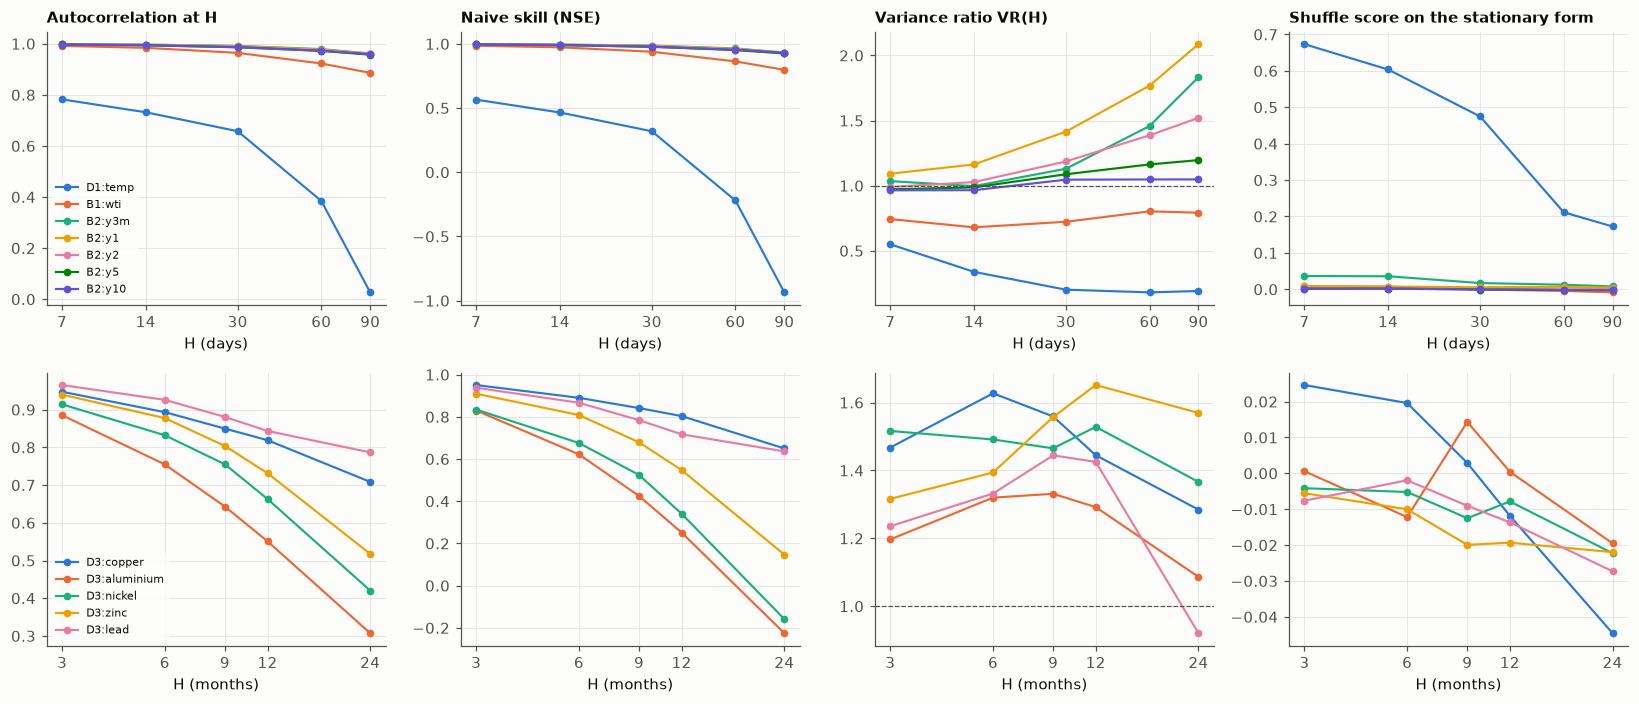

In [7]:
measures = [("acf_H", "Autocorrelation at H"), ("nse_naive", "Naive skill (NSE)"),
            ("vr", "Variance ratio VR(H)"), ("eta_structure", "Shuffle score on the stationary form")]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for row, grain in enumerate(["daily", "monthly"]):
    sub = by_h[by_h["grain"] != "monthly"] if grain == "daily" else by_h[by_h["grain"] == "monthly"]
    for col, (m, title) in enumerate(measures):
        ax = axes[row, col]
        for i, (name, g) in enumerate(sub.groupby("series", sort=False)):
            ax.plot(g["H"], g[m], marker="o", ms=4, color=COLORS[i % len(COLORS)], label=name)
        if m == "vr":
            ax.axhline(1, color=INK_2, lw=0.8, ls="--")
        ax.set_xscale("log")
        ax.minorticks_off()                                    # only the five horizons as ticks
        ax.set_xticks(sub["H"].unique(), [str(h) for h in sub["H"].unique()])
        ax.set_title(title if row == 0 else "", loc="left", fontsize=10)
        ax.set_xlabel(f"H ({'days' if grain == 'daily' else 'months'})")
    axes[row, 0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_03_forecastability_by_horizon.png", dpi=150)
plt.show()

In [8]:
lines = []
for name, g in by_h.groupby("series", sort=False):
    first, last = g.iloc[0], g.iloc[-1]
    rw = (g["vr_p"] > 0.05).all()
    lines.append(f"{name}: naive NSE {first['nse_naive']:.2f} at H={first['H']} -> {last['nse_naive']:.2f} at H={last['H']}; "
                 f"seasonal naive {last['nse_seasonal_naive']:.2f} at H={last['H']}; "
                 f"VR {'consistent with a random walk at every H' if rw else 'differs from 1 at some H'}; "
                 f"order beyond persistence (eta, stationary form) {g['eta_structure'].max():.2f} at best")
print("\n".join(lines))

D1:temp: naive NSE 0.56 at H=7 -> -0.94 at H=90; seasonal naive 0.49 at H=90; VR differs from 1 at some H; order beyond persistence (eta, stationary form) 0.67 at best
D3:copper: naive NSE 0.95 at H=3 -> 0.65 at H=24; seasonal naive 0.65 at H=24; VR differs from 1 at some H; order beyond persistence (eta, stationary form) 0.02 at best
D3:aluminium: naive NSE 0.83 at H=3 -> -0.23 at H=24; seasonal naive -0.23 at H=24; VR consistent with a random walk at every H; order beyond persistence (eta, stationary form) 0.01 at best
D3:nickel: naive NSE 0.83 at H=3 -> -0.16 at H=24; seasonal naive -0.16 at H=24; VR differs from 1 at some H; order beyond persistence (eta, stationary form) -0.00 at best
D3:zinc: naive NSE 0.91 at H=3 -> 0.15 at H=24; seasonal naive 0.15 at H=24; VR differs from 1 at some H; order beyond persistence (eta, stationary form) -0.01 at best
D3:lead: naive NSE 0.94 at H=3 -> 0.64 at H=24; seasonal naive 0.64 at H=24; VR consistent with a random walk at every H; order beyon

**What this tells us.** Temperature is the only series with clear structure beyond persistence. Its shuffle score
falls from 0.67 at 7 days to 0.17 at 90 days. By 90 days the naive forecast is worse than the mean (NSE −0.94),
while the seasonal naive forecast (the same day last year) holds at 0.49 at every horizon, so at long horizons the
annual cycle is most of what can be forecast. The metals, WTI and the yields have naive skill close to 1 because
their levels barely move from one step to the next. Their shuffle scores on changes stay near zero; the best is
copper's 0.025 at 3 months.

The variance ratios add detail. Temperature falls far below 1 (0.55 to 0.19), the signature of a stationary,
mean-reverting series. The short yields drift above 1 at 60 to 90 days (the 1-year yield reaches 2.1), which is
trending behaviour. WTI sits at 0.7 to 0.8, but its fat tails keep the robust test from rejecting a random walk.
The monthly metals sit at 1.1 to 1.65, significantly above 1 at short horizons for copper, nickel and zinc. Most of
that is an artefact of averaging: the changes of a monthly average of a random walk have a first-order
autocorrelation close to 0.25, and that alone lifts the variance ratio to about 1.33 at 3 months and 1.46 at 12
months (Section 3b).

High naive skill is a property of the level, not a sign that a series is easy. What a model can add beyond the
naive forecast is measured on the changes, and there it is small for every series except temperature.

## 3 · View B: linear structure

How much of the next value, or the next change, can a linear model anticipate from the recent past? Fit the best
linear autoregression to the stationary form and ask what share of the variance it explains one step ahead. If
the answer is close to zero, no linear combination of past values helps.

The share of variance an autoregression explains is

$$R^2_{AR} = 1 - \frac{\hat\sigma^2_e}{\hat\sigma^2_y}, \tag{4}$$

where $\hat\sigma^2_e$ is the residual variance of the AIC-best AR($p$) model ($p \le 30$ for daily data, 24 for
monthly) and $\hat\sigma^2_y$ the variance of the stationary form. It estimates the one-step $R^2_1$ of equation
(0) for the best *linear* forecast. For the price changes it measures how much of the next change a linear model
can anticipate.

Compare it with the same fit on the shuffled copy, which is close to 0. For temperature the input is the
stationary level, so $R^2_{AR}$ includes day-to-day persistence; for a stationary series that persistence is real,
usable structure, because the series returns to its seasonal mean. For changes, it is what remains after
persistence. It is a one-step figure: the shuffle score $\eta_H$ of Section 2 shows whether the structure survives
to the forecast horizons.

The measure suits any stationary series, or the changes of a non-stationary one, and it is fast and stable. It
misses non-linear structure; Section 4 and the non-linearity tests of Notebook 01 look for that.

In [9]:
srows = []
for d, c in TARGETS:
    z, view = structure_view(d, c)
    lags = 24 if DATASETS[d]["grain"] == "monthly" else 30
    ar = ar_variance_explained(z.to_numpy(), lags)
    srows.append({"series": f"{d}:{c}", "view": view, "ar_order": ar["ar_order"], "ar_r2": ar["var_explained"],
                  "ar_r2_shuffled": ar_variance_explained(shuffled(z), lags)["var_explained"],
                  "acf1": acf_at(z.to_numpy(), [1])[1]})
structure = pd.DataFrame(srows).set_index("series")
structure.round(3)

,view,ar_order,ar_r2,ar_r2_shuffled,acf1
series,,,,,
D1:temp,level,23,0.898,0.002,0.943
D3:copper,log change,11,0.184,0.000,0.357
D3:aluminium,log change,6,0.061,0.000,0.203
D3:nickel,log change,1,0.107,0.018,0.327
D3:zinc,log change,1,0.065,0.000,0.255
D3:lead,log change,1,0.029,0.000,0.170
B1:wti,change,29,0.030,0.000,-0.117
B2:y3m,change,29,0.062,0.001,0.124
B2:y1,change,23,0.014,0.000,0.070


### 3b · An artefact that imitates structure: monthly averaging

The metal prices of D3 are **monthly averages** of daily prices, and averaging creates structure of its own. If a
price follows a random walk and we average it over $m$ sub-periods, the first differences of the averages have
lag-1 autocorrelation

$$\rho_1 = \frac{m^2 - 1}{2(2m^2 + 1)} \ \to\  0.25 \quad (m \to \infty), \tag{4b}$$

and no autocorrelation beyond lag 1, even though the underlying daily price is unpredictable. That correlation is
real in the monthly data, and a model can use it one month ahead, but it says nothing about how metal markets
behave, and it does not reach the 3-month horizon. The same correlation lifts the variance ratio of Section 2. With
a lag-1 correlation $\rho_1$ and none beyond,

$$\mathrm{VR}(k) = 1 + 2\rho_1\thinspace \frac{k-1}{k},$$

which is about 1.33 at 3 months and 1.46 at 12 months for $\rho_1 = 0.25$. It looks like momentum but is only
averaging.

To see which part of the metals' structure this effect alone explains, the cell below simulates it 200 times: a
Gaussian daily random walk, 21 trading days a month, averaged to 535 months (the length of D3) and then
differenced. Every structure measure that is later read for the metals is computed on these simulated series, and
their 5–95 % range becomes the **averaging reference**. A metal that sits inside that range shows no structure
beyond what averaging creates.

In [10]:
rng, t0 = np.random.default_rng(1960), time.time()
n_months, days = len(SNAP["D3"]["copper"].dropna()), 21
SIM = [np.diff(np.cumsum(rng.standard_normal(n_months * days)).reshape(n_months, days).mean(axis=1))
       for _ in range(200)]


def averaging_reference(measure):
    """5 %, median and 95 % of a measure over the 200 simulated monthly averages."""
    return pd.Series(np.percentile([measure(z) for z in SIM], [5, 50, 95]), index=["5 %", "median", "95 %"])


averaging = pd.DataFrame({"acf1": averaging_reference(lambda z: acf_at(z, [1])[1]),
                          "ar_r2": averaging_reference(lambda z: ar_variance_explained(z, 24)["var_explained"])}).T
print(f"200 simulated monthly averages of a daily random walk in {time.time() - t0:.0f} s; "
      f"Working's formula for m = {days}: rho_1 = {(days**2 - 1) / (2 * (2 * days**2 + 1)):.3f}")
metals = structure.loc[[f"D3:{m}" for m in METALS], ["acf1", "ar_r2"]]
print("\nThe metals against the averaging reference (inside = no more than averaging alone produces):")
for name, r in metals.iterrows():
    cells = []
    for col in ["acf1", "ar_r2"]:
        lo, hi = averaging.loc[col, "5 %"], averaging.loc[col, "95 %"]
        where = "inside" if lo <= r[col] <= hi else "above" if r[col] > hi else "below"
        cells.append(f"{col} {r[col]:.3f} ({where})")
    print(f"  {name:14s} " + ", ".join(cells))
averaging.round(3)

200 simulated monthly averages of a daily random walk in 3 s; Working's formula for m = 21: rho_1 = 0.249

The metals against the averaging reference (inside = no more than averaging alone produces):
  D3:copper      acf1 0.357 (above), ar_r2 0.184 (above)
  D3:aluminium   acf1 0.203 (inside), ar_r2 0.061 (inside)
  D3:nickel      acf1 0.327 (above), ar_r2 0.107 (inside)
  D3:zinc        acf1 0.255 (inside), ar_r2 0.065 (inside)
  D3:lead        acf1 0.170 (below), ar_r2 0.029 (below)


,5 %,median,95 %
acf1,0.185,0.250,0.310
ar_r2,0.037,0.072,0.111


**What this tells us.** Temperature's level is highly predictable one day ahead: an AR(23) explains 90 % of its
variance, against 0.2 % for its shuffled copy. That is persistence around the seasonal cycle, and for a stationary
series it is usable structure. For the changes of the other series the shares are small. Copper is highest
(AR(11), 18 %), then nickel (11 %), zinc (6.5 %), the 3-month yield (6.2 %) and aluminium (6.1 %); WTI, lead and
the other yields explain 3 % or less, and the 5- and 10-year yields only 0.4 %.

The averaging simulation explains most of the metals' structure. Equation (4b) gives ρ₁ = 0.249 for 21 trading
days, and the 200 simulated series give, from averaging alone, a lag-1 autocorrelation of 0.19 to 0.31 and an AR R²
of 0.04 to 0.11 (5 to 95 %). Aluminium and zinc sit inside both ranges and lead below them. Nickel's lag-1
autocorrelation (0.33) is just above the range, but its AR R² (0.11) is inside. Only copper exceeds both (0.36 and
0.18).

A model that exploits the one-month correlation of aluminium, nickel, zinc or lead is exploiting the way the data
are averaged, not the behaviour of metal markets, and the effect is gone by the 3-month horizon. Copper is the only
metal where a model may find a little more.

## 4 · View B: entropy and complexity

Entropy measures how surprising a series is: low entropy means repeated, predictable patterns. Each estimator
below looks at a different kind of pattern.

- *Spectral entropy* asks whether the variance is concentrated in a few frequencies (cycles) or spread over all of
  them, as in noise.
- *Permutation entropy* looks only at the up-and-down order of a few consecutive values, ignoring their size.
- *Sample entropy* asks whether stretches of the series that look alike stay alike one step later.
- *SVD entropy* asks how many independent shapes are needed to describe short windows of the series.
- *Multiscale entropy* repeats sample entropy on block averages, to see whether structure exists at longer scales.
- The *complexity–entropy plane* places a series between noise, correlated noise and chaos.

#### Spectral entropy and $\Omega$

Estimate the spectral density with Welch's method and normalise it so that it sums to 1 over the $N_f$
frequencies, giving $\hat f(\lambda_j)$. Then

$$H_{\text{spec}} = -\frac{1}{\log N_f}\sum_{j=1}^{N_f} \hat f(\lambda_j)\log \hat f(\lambda_j) \in [0, 1], \qquad \Omega = 1 - H_{\text{spec}}. \tag{5}$$

$\Omega$, the forecastability measure of forecastable component analysis (ForeCA), is 0 for white noise, whose
spectrum is flat, and 1 for a pure sine wave.

#### Permutation entropy

Take every run of $d = 4$ consecutive values and record only their ordinal pattern (which value is largest, which
is second, and so on). Permutation entropy is the Shannon entropy of the frequencies of the $d! = 24$ possible
patterns, divided by $\log d!$, so 1 means every ordering is equally likely. (6)

#### Sample entropy

Count the pairs of stretches of length 2 that lie within a tolerance $r = 0.2\thinspace s$ of each other ($B$), and the
pairs that still lie within $r$ when both stretches are extended to length 3 ($A$). Then

$$\mathrm{SampEn} = -\log \frac{A}{B}. \tag{7}$$

If stretches that start alike usually stay alike, $A$ is close to $B$ and the entropy is low: the series is
regular.

#### Multiscale entropy

Sample entropy of the averages of non-overlapping blocks of $\tau$ points, for $\tau = 1, 2, 5, 10, 20$, with $r$
fixed from the original series. White noise loses entropy quickly as $\tau$ grows; structured long-memory series
keep it. (8)

#### SVD entropy

The entropy of the normalised singular values of the delay matrix with embedding dimension 4 (each row holds four
consecutive values). It is low when a few patterns dominate. (9)

#### The complexity–entropy plane

Plot the permutation entropy $H$ against the Jensen–Shannon statistical complexity

$$C = Q_{JS}[P, P_e]\thinspace H, \tag{10}$$

where $Q_{JS}$ measures how far the distribution of ordinal patterns $P$ is from the uniform distribution $P_e$.
White noise sits at $H = 1, C = 0$; chaotic systems sit high, near the curve of maximal complexity, at intermediate
$H$; correlated noise lies in between.

#### How to read them

Only the gap to the shuffled copy counts. $\Omega$ is the easiest to read, as the share of the spectrum that is not
flat: $\Omega = 0.6$ means a strongly cyclical series, while a short noisy series can show an $\Omega$ near 0.07
from estimation noise alone. A permutation entropy close to 1 means the up-and-down sequences look random. A sample
entropy well below the shuffled value means that patterns recur. In the multiscale panel, noise falls steadily with
scale; a curve that stays flat or rises shows structure at longer scales.

These measures are useful on long stationary series, to ask whether there is any pattern at all, linear or not.
Three limits apply. The input must be stationary: on a trending level every entropy reports persistence as
structure. Short series give noisy estimates: with 534 monthly changes, multiscale entropy at scale 20 would rest
on 26 points, too few for sample entropy, so it is not computed. And long runs of identical values, such as zeros,
lower sample and permutation entropy without making the series any more forecastable.

In [11]:
def entropy_measures(x, order=4):
    """Spectral entropy / ForeCA Omega, permutation, sample and SVD entropy.

    All normalised to [0, 1] where possible; lower entropy = more structure.
    Omega = 1 - H_spectral (Goerg, 2013): the share of the spectrum that is
    not flat, 0 for white noise and 1 for a pure sinusoid.
    """
    import antropy as ant

    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    h_spec = float(ant.spectral_entropy(x, sf=1.0, method="welch", normalize=True,
                                        nperseg=min(len(x), 512)))
    return {
        "spectral_entropy": h_spec, "foreca_omega": 1 - h_spec,
        "perm_entropy": float(ant.perm_entropy(x, order=order, delay=1, normalize=True)),
        "sample_entropy": float(ant.sample_entropy(x, order=2)),
        "svd_entropy": float(ant.svd_entropy(x, order=order, delay=1, normalize=True)),
    }


def multiscale_entropy(x, scales=(1, 2, 5, 10, 20)):
    """Sample entropy of coarse-grained series (Costa, Goldberger & Peng, 2002).

    The tolerance r = 0.2 SD is fixed from the original series, as in Costa et al.
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    r = 0.2 * x.std(ddof=0)
    out = {}
    for s in scales:
        n = len(x) // s
        cg = x[: n * s].reshape(n, s).mean(axis=1)
        out[s] = float(_sampen_fixed_r(cg, 2, r)) if n > 50 else np.nan
    return out


def _sampen_fixed_r(x, m, r):
    """Sample entropy with an absolute tolerance r (Richman & Moorman, 2000)."""
    x = np.asarray(x, float)
    n = len(x)

    def count(mm):
        emb = np.lib.stride_tricks.sliding_window_view(x, mm)[: n - m]
        c = 0
        for i in range(len(emb) - 1):
            d = np.max(np.abs(emb[i + 1:] - emb[i]), axis=1)
            c += np.sum(d <= r)
        return c

    b, a = count(m), count(m + 1)
    return -np.log(a / b) if a > 0 and b > 0 else np.inf


def complexity_entropy(x, dx=4):
    """Normalised permutation entropy H and Jensen-Shannon complexity C (Rosso et al., 2007)."""
    import ordpy

    x = np.asarray(x, float)
    h, c = ordpy.complexity_entropy(x[~np.isnan(x)], dx=dx)
    return {"pe_H": float(h), "js_C": float(c)}

In [12]:
erows, nrows, mse_rows, t0 = [], [], {}, time.time()
for d, c in TARGETS:
    z = structure_view(d, c)[0].to_numpy()
    erows.append({"series": f"{d}:{c}", **entropy_measures(z), **complexity_entropy(z)})
    nrows.append({"series": f"{d}:{c}", **entropy_measures(shuffled(z)), **complexity_entropy(shuffled(z))})
    mse_rows[f"{d}:{c}"] = multiscale_entropy(z)
entropy = pd.DataFrame(erows).set_index("series")
entropy_noise = pd.DataFrame(nrows).set_index("series")
mse = pd.DataFrame(mse_rows).T
averaging.loc["foreca_omega"] = averaging_reference(lambda z: entropy_measures(z)["foreca_omega"])
print(f"entropy measures in {time.time() - t0:.0f} s")
print(f"Averaging reference (5-95 %) for the monthly metals: Omega {averaging.loc['foreca_omega', '5 %']:.3f} "
      f"to {averaging.loc['foreca_omega', '95 %']:.3f}")
show = ["foreca_omega", "perm_entropy", "sample_entropy", "svd_entropy", "js_C"]
pd.concat({"series": entropy[show], "shuffled": entropy_noise[show]}, axis=1).swaplevel(axis=1)[show].round(3)

entropy measures in 57 s
Averaging reference (5-95 %) for the monthly metals: Omega 0.073 to 0.102


foreca_omega          perm_entropy          sample_entropy          svd_entropy            js_C         
                   series shuffled       series shuffled         series shuffled      series shuffled series shuffled
series                                                                                                               
D1:temp             0.602    0.003        0.938    1.000          1.090    2.202       0.434    0.821  0.073    0.000
D3:copper           0.097    0.075        0.984    0.996          1.964    2.051       0.981    1.000  0.021    0.005
D3:aluminium        0.082    0.064        0.990    0.996          1.946    2.169       0.994    1.000  0.013    0.005
D3:nickel           0.094    0.072        0.979    0.991          1.822    2.054       0.984    0.999  0.027    0.011
D3:zinc             0.079    0.067        0.993    0.997          1.923    2.239       0.991    1.000  0.009    0.003
D3:lead             0.078    0.077        0.987    0.994          1.950    2.066       0.996    1.000  0.017    0.009
B1:wti              0.009    0.003        0.999    1.000          1.041    1.606       0.998    1.000  0.001    0.001
B2:y3m              0.018    0.003        0.983    0.994          0.663    1.094       0.997    1.000  0.021    0.008
B2:y1               0.007    0.003        0.990    0.996          1.704    2.347       0.999    1.000  0.013    0.005
B2:y2               0.005    0.003        0.996    0.998          1.417    1.697       1.000    1.000  0.005    0.003
B2:y5               0.005    0.003        0.999    0.999          1.725    1.846       1.000    1.000  0.002    0.001
B2:y10              0.004    0.003        0.999    0.999          1.750    1.846       1.000    1.000  0.002    0.001

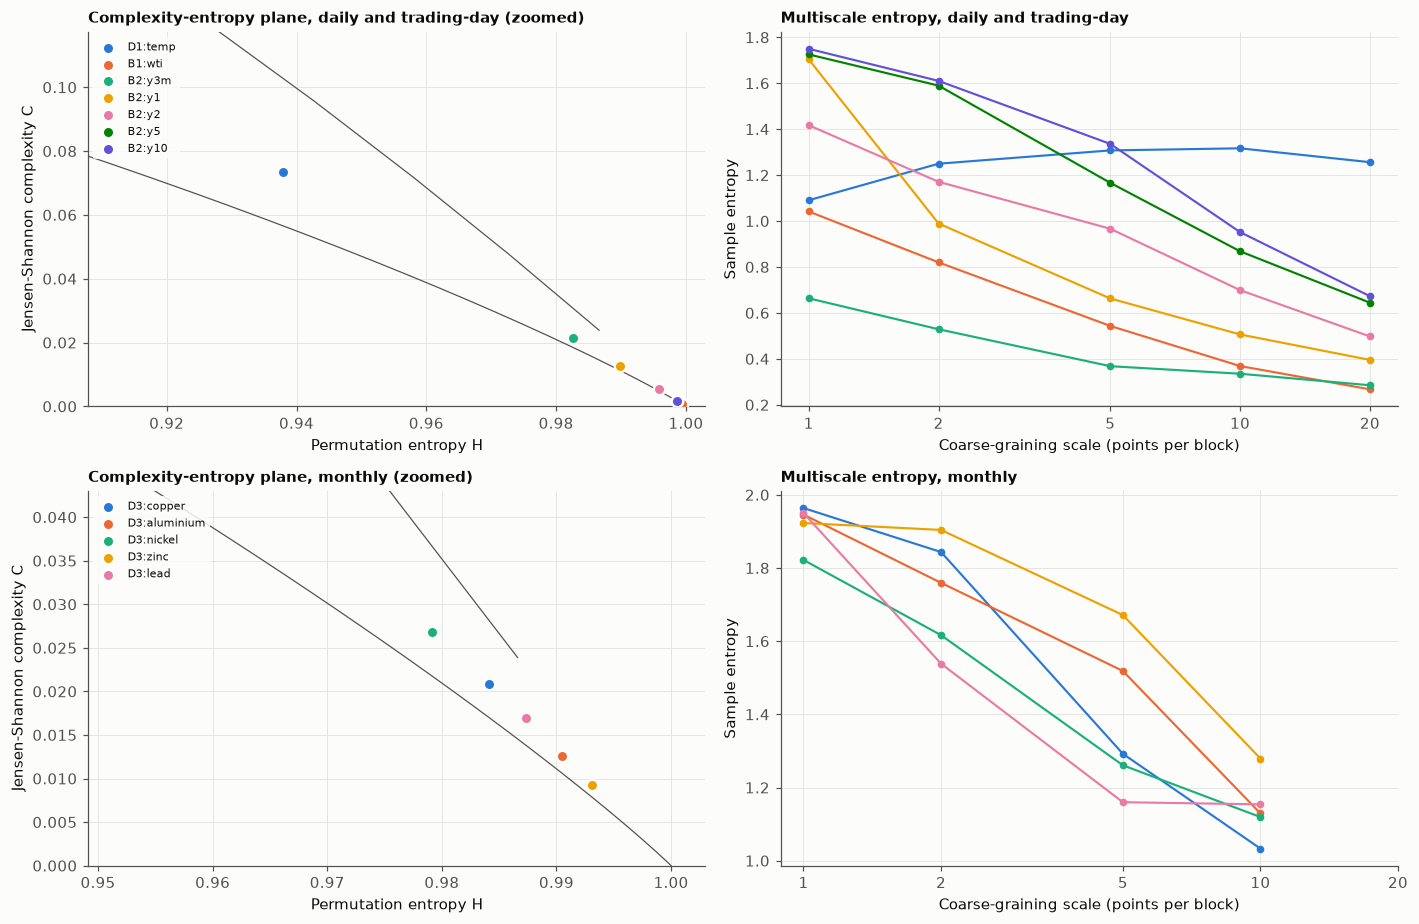

In [13]:
import ordpy

# one row per grain, as in the horizon figure, so each series keeps its colour in both figures
order = list(by_h["series"].unique())
groups = {"daily and trading-day": [s for s in order if not s.startswith("D3")],
          "monthly": [s for s in order if s.startswith("D3")]}
hmax, cmax = ordpy.maximum_complexity_entropy(dx=4).T
hmin, cmin = ordpy.minimum_complexity_entropy(dx=4, size=200).T
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for row, (grain, names) in enumerate(groups.items()):
    ax = axes[row, 0]
    ax.plot(hmax, cmax, color=INK_2, lw=0.8)
    ax.plot(hmin, cmin, color=INK_2, lw=0.8)
    for i, name in enumerate(names):
        r = entropy.loc[name]
        ax.scatter(r["pe_H"], r["js_C"], s=55, color=COLORS[i], edgecolor="white", linewidth=1.5, zorder=3,
                   label=name)
    sub = entropy.loc[names]
    ax.set_xlim(sub["pe_H"].min() - 0.03, 1.003)            # zoomed: every series sits near H = 1
    ax.set_ylim(0, sub["js_C"].max() * 1.6)
    ax.set_xlabel("Permutation entropy H")
    ax.set_ylabel("Jensen-Shannon complexity C")
    ax.set_title(f"Complexity-entropy plane, {grain} (zoomed)", loc="left", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
    ax = axes[row, 1]
    for i, name in enumerate(names):
        r = mse.loc[name].dropna()
        ax.plot(r.index.astype(int), r.values, marker="o", ms=4, color=COLORS[i], label=name)
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks([1, 2, 5, 10, 20], ["1", "2", "5", "10", "20"])
    ax.set_xlabel("Coarse-graining scale (points per block)")
    ax.set_ylabel("Sample entropy")
    ax.set_title(f"Multiscale entropy, {grain}", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_03_entropy.png", dpi=150)
plt.show()

### 4b · What low sample entropy is made of in financial series

WTI and several yields have a sample entropy well below their shuffled copies, although Section 2 found almost no
order in their changes. How can that be? Sample entropy compares the *sizes* of nearby values with a fixed
tolerance $r$. In a calm spell every change is small, so stretches of calm look alike and stay alike. The measure
therefore reads **volatility clustering**, the alternation of calm and turbulent spells, as regularity.

A direct check: divide each change by the standard deviation of the previous 20 changes, which removes the spells,
and compute sample entropy again. If the gap to the shuffled copy closes, the regularity was in the size of the
changes, not in their direction. That kind of structure helps to decide how wide a forecast interval should be,
not where the level goes.

In [14]:
vrows = []
for d, c in [(d, c) for d, c in TARGETS if d in ("B1", "B2")]:
    z = structure_view(d, c)[0]
    scaled = (z / z.rolling(20).std().shift(1)).replace([np.inf, -np.inf], np.nan).dropna()
    vrows.append({"series": f"{d}:{c}", "share of exact zeros": (z == 0).mean(),
                  "sample entropy": entropy.loc[f"{d}:{c}", "sample_entropy"],
                  "shuffled": entropy_noise.loc[f"{d}:{c}", "sample_entropy"],
                  "volatility-scaled": entropy_measures(scaled.to_numpy())["sample_entropy"],
                  "volatility-scaled, shuffled": entropy_measures(shuffled(scaled))["sample_entropy"]})
spells = pd.DataFrame(vrows).set_index("series")
spells["gap closed"] = 1 - ((spells["volatility-scaled, shuffled"] - spells["volatility-scaled"])
                            / (spells["shuffled"] - spells["sample entropy"]))
spells.round(3)

,share of exact zeros,sample entropy,shuffled,volatility-scaled,"volatility-scaled, shuffled",gap closed
series,,,,,,
B1:wti,0.012,1.041,1.606,2.015,2.040,0.955
B2:y3m,0.238,0.663,1.094,1.609,1.851,0.437
B2:y1,0.185,1.704,2.347,1.810,1.972,0.748
B2:y2,0.155,1.417,1.697,1.982,2.043,0.783
B2:y5,0.088,1.725,1.846,2.046,2.075,0.757
B2:y10,0.082,1.750,1.846,2.075,2.098,0.761


**What this tells us.** Temperature stands apart on every entropy measure, and each gap to its shuffled copy is
large: Ω 0.60 against 0.003, sample entropy 1.09 against 2.20, SVD entropy 0.43 against 0.82, and it is the only
point clearly inside the complexity–entropy plane (H = 0.94, C = 0.07; shuffled: H = 1, C = 0).

The metals look structured at first sight (Ω 0.08 to 0.10), but their shuffled copies already reach 0.06 to 0.08:
on 534 points the spectrum is estimated from one 512-point segment and is noisy, so even noise does not look flat.
All five metals also sit inside the averaging range of 0.073 to 0.102, so their spectra hold nothing beyond the
averaging effect. WTI and the yields have Ω of 0.02 or below, close to their shuffled 0.003, and sit at H ≈ 1,
C ≈ 0, where white noise sits.

Sample entropy is the exception: WTI (1.04 against 1.61) and the yields sit clearly below their shuffled copies,
although their changes have almost no order. Section 4b shows why. Once each change is divided by the volatility of
the previous 20 days, 96 % of WTI's gap and 75 to 78 % of the gap for the 1- to 10-year yields disappear: the
regularity was the alternation of calm and turbulent spells. For the 3-month yield only 44 % of the gap closes. The
rest comes from the zero lower bound. On the 23 % of days with the yield below 0.25 % (2009 to 2015 and 2020 to
2021), 45 % of the daily changes are exactly zero, against 18 % on other days, and those runs of zeros look regular
without being a pattern a model can exploit.

In the multiscale panels, sample entropy falls with coarse-graining for the economic series, as it does for
uncorrelated noise. Temperature's entropy instead rises and then levels off, the sign of structure across scales.

Read against noise, then, the entropies point to one series with real pattern, temperature. For the financial
series they find structure in the size of the changes, which helps a probabilistic model set the width of its
intervals but not the direction of its point forecast.

## 5 · View B: decomposition shares

How much of the variance sits in slow, smooth components? Slow components change little within a forecast
horizon, so they are the easiest part to extrapolate. The idea is to split the series into oscillations, from the
fastest to the slowest, and add up the variance of those slower than the shortest forecast horizon.

Empirical mode decomposition (EMD) splits a series into *intrinsic mode functions* by repeatedly removing the mean
of its upper and lower envelopes, from the fastest oscillation to the slowest, plus a residual trend:

$$y_t = \sum_k c_{k,t} + r_t.$$

Variational mode decomposition (VMD) instead looks for $K = 5$ modes $u_k$, each concentrated around a centre
frequency $\omega_k$, by solving

$$\min_{\lbrace u_k\rbrace,\lbrace\omega_k\rbrace} \sum_{k=1}^{K} \left\lVert \partial_t\negthinspace\left[\left(\delta(t) + \frac{i}{\pi t}\right) \ast u_k(t)\right] e^{-i\omega_k t} \right\rVert_2^2 \quad \text{subject to} \quad \sum_{k=1}^{K} u_k = y.$$

The term in square brackets turns each mode into its complex (analytic) form, the factor $e^{-i\omega_k t}$ shifts
it down to zero frequency, and the derivative penalises any spread around $\omega_k$. The **low-frequency share**
is the share of the summed mode variances in modes slower than the shortest forecast horizon $P$ (7 days or 3
months). Each mode's period comes from its zero crossings for EMD and is $2\pi/\omega_k$ for VMD.

#### How to read it

Again, against noise. White noise spreads its variance evenly over frequencies from 0 to 0.5 cycles per step.
Periods longer than $P$ are frequencies below $1/P$, so noise alone puts about $2/P$ of its variance in slow modes:
0.29 for $P = 7$ days and 0.67 for $P = 3$ months. Because the bands of the modes are broad and overlap, each
method's own value on the shuffled copy is the fairer reference. A share well above it means slow, smooth
components, and the VMD centre periods name them (a period near 365 days is the annual cycle).

The measure is useful when a series has cycles at known periods (seasons, business cycles) and you want to know how
much they matter. It has limits: EMD can mix several periods in one mode; VMD needs the number of modes chosen in
advance; and when the shortest horizon is close to the shortest period the data can show (3 months against 2
months for monthly data), almost everything counts as slow, so the measure separates little.

In [15]:
def mean_period(component):
    """Mean period of a mode from its zero crossings: n / (crossings / 2)."""
    c = np.asarray(component, float) - np.mean(component)
    crossings = np.sum(np.signbit(c[1:]) != np.signbit(c[:-1]))
    return len(c) / max(crossings / 2, 0.5)


def emd_low_frequency_share(x, threshold_period, max_imf=10):
    """Share of variance in EMD modes (plus residue) slower than threshold_period.

    Empirical mode decomposition (Huang et al., 1998) splits the series into
    intrinsic mode functions from fast to slow. Variances of modes are not
    exactly additive, so shares are computed over the sum of mode variances.
    """
    from PyEMD import EMD

    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    imfs = EMD().emd(x, max_imf=max_imf)
    var = np.array([np.var(m) for m in imfs])
    slow = np.array([mean_period(m) >= threshold_period for m in imfs])
    slow[-1] = True  # the residue (trend) is always slow
    return {"n_modes": len(imfs), "low_freq_share": float(var[slow].sum() / var.sum())}


def vmd_low_frequency_share(x, threshold_period, k=5, alpha=2000):
    """Share of variance in VMD modes whose centre period exceeds threshold_period.

    Variational mode decomposition (Dragomiretskiy & Zosso, 2014) with K modes
    and bandwidth penalty alpha; centre frequencies are in cycles per sample.
    """
    from vmdpy import VMD

    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) % 2:
        x = x[1:]
    u, _, omega = VMD(x - x.mean(), alpha, 0.0, k, 0, 1, 1e-7)
    centre = np.maximum(omega[-1], 1e-12)  # final centre frequencies (cycles / sample)
    var = np.var(u, axis=1)
    slow = (1 / centre) >= threshold_period
    return {"low_freq_share": float(var[slow].sum() / var.sum()),
            "centre_periods": [float(1 / c) for c in centre]}

In [16]:
drows, t0 = [], time.time()
for d, c in TARGETS:
    z = structure_view(d, c)[0].to_numpy()
    thr = 3 if DATASETS[d]["grain"] == "monthly" else 7
    emd = emd_low_frequency_share(z, thr)
    vmd = vmd_low_frequency_share(z, thr)
    drows.append({"series": f"{d}:{c}", "emd_modes": emd["n_modes"], "emd_low_share": emd["low_freq_share"],
                  "emd_low_share_shuffled": emd_low_frequency_share(shuffled(z), thr)["low_freq_share"],
                  "vmd_low_share": vmd["low_freq_share"],
                  "vmd_low_share_shuffled": vmd_low_frequency_share(shuffled(z), thr)["low_freq_share"],
                  "white_noise_share": 2 / thr,
                  "vmd_periods": ", ".join(f"{p:.0f}" for p in vmd["centre_periods"])})
decomposition = pd.DataFrame(drows).set_index("series")
print(f"decompositions in {time.time() - t0:.0f} s")
decomposition.round(3)

decompositions in 47 s


,emd_modes,emd_low_share,emd_low_share_shuffled,vmd_low_share,vmd_low_share_shuffled,white_noise_share,vmd_periods
series,,,,,,,
D1:temp,11,0.929,0.230,0.987,0.200,0.286,"351, 37, 18, 10, 7"
D3:copper,8,1.000,0.457,0.903,0.801,0.667,"28, 11, 6, 4, 3"
D3:aluminium,8,1.000,0.404,0.814,0.780,0.667,"29, 9, 5, 4, 3"
D3:nickel,8,0.613,0.447,0.895,0.766,0.667,"39, 9, 5, 4, 3"
D3:zinc,8,0.557,0.388,0.886,0.787,0.667,"38, 9, 5, 4, 2"
D3:lead,8,1.000,0.426,0.861,0.719,0.667,"30, 9, 6, 4, 3"
B1:wti,11,0.214,0.302,0.166,0.390,0.286,"14, 6, 4, 3, 2"
B2:y3m,11,0.291,0.353,0.183,0.395,0.286,"17, 7, 5, 4, 2"
B2:y1,11,0.288,0.310,0.411,0.397,0.286,"20, 7, 5, 3, 2"


**What this tells us.** Temperature stands out again. 93 % (EMD) and 99 % (VMD) of its variance sits in modes
slower than 7 days, against 23 % and 20 % for its shuffled copy, and VMD's slowest mode has a centre period of 351
days: the annual cycle.

For the metals, VMD puts 81 to 90 % of the variance in modes slower than 3 months, 0.03 to 0.14 more than their
shuffled copies, in the direction the averaging effect predicts (averaging smooths the series, and the one-month
correlation adds low-frequency variance). But on monthly data with a 3-month threshold, noise alone already puts
about two thirds of its variance in "slow" modes, so the measure separates little. EMD's share of 1.00 for copper,
aluminium and lead only means that even its fastest mode has a mean period of at least 3 months by the
zero-crossing count.

For the yields, both methods give shares within 0.02 of their shuffled copies, or below them. WTI and the 3-month
yield are well below (VMD 0.17 and 0.18 against 0.39); for WTI this matches its negative lag-1 autocorrelation
(−0.12), which moves variance towards the fastest frequencies.

Only temperature, then, has slow components that make long-horizon forecasts easier, and the main one is the
annual cycle, which the seasonal naive forecast and the Fourier covariates of D2 already carry.

## 6 · View B: long memory and the predictability horizon

Two questions here. Does the past matter over long spans (long memory), which would make a long context worth
giving a model? And is the series chaotic, with a hard limit on how far ahead any forecast can be useful?

#### Detrended fluctuation analysis

DFA measures how the typical size of the fluctuations grows with the length of the window, after removing a local
trend in each window (Notebook 01 gives the details). Without memory it grows like the square root of the window
length, so $\alpha \approx 0.5$; with long memory it grows faster, $0.5 < \alpha < 1$. Here it is computed on the
stationary form.

#### The largest Lyapunov exponent

The Lyapunov exponent $\lambda$ measures how fast two stretches of the series that start almost alike drift apart.
The series is first turned into a cloud of delay vectors (a reconstructed phase space). For each delay vector we
find its nearest neighbour, excluding points close in time, follow both for $i$ steps and fit the slope of the
average log distance,

$$\langle \ln d_j(i) \rangle \approx \ln d_j(0) + \lambda\thinspace i .$$

A chaotic system has $\lambda > 0$: small differences grow exponentially, and any forecast loses its value after
about $\tau_f \approx 1/\lambda$ steps.

#### How to read them

For DFA, compare with the shuffled copy, which gives about 0.5. For the short monthly series we use the mean of 20
shuffles, because a single shuffle of 534 points moves $\alpha$ by about 0.03. A value between 0.5 and 1 means the
past keeps mattering over long spans, and longer contexts can help at long horizons. A value above 1 means
something non-stationary is still in the input, such as a seasonal cycle or a trend. For the Lyapunov exponent,
only a value clearly above its shuffled value means anything, and even then a switch between regimes can produce
it.

DFA helps to decide how much history to give a model and whether long horizons can draw on long memory; it needs
long series. The Lyapunov horizon was designed for low-noise deterministic systems (lasers, electronic circuits,
some physical processes), and on economic data it is mainly a check. Its estimation method has a known weakness
that we show rather than hide: on noisy data it returns a small positive $\lambda$ even for pure noise. So every
estimate is set next to the same estimate on a shuffled copy, and only a clear difference means anything.

In [17]:
def dfa_alpha(x):
    """Detrended fluctuation analysis exponent (Peng et al., 1994) via nolds.

    The slope is fitted by least squares (fit_exp="poly"): nolds' default RANSAC
    fit samples at random, so it gives a slightly different answer on every run.
    """
    import nolds

    x = np.asarray(x, float)
    return float(nolds.dfa(x[~np.isnan(x)], fit_exp="poly"))


def lyapunov_horizon(x, max_points=3000, emb_dim=6, seed=0):
    """Largest Lyapunov exponent (Rosenstein et al., 1993) and tau_f = 1 / lambda.

    Uses the most recent `max_points` points (the method compares every pair of
    delay vectors). On noisy data the estimate is biased, so it is also computed
    on a shuffled copy: only a lambda clearly different from the shuffled one
    says anything about the series. A non-positive lambda gives tau_f = inf.
    The slope is fitted with nolds' default RANSAC, a robust line fit that is not
    pulled by the first jump or the flat tail of the divergence curve. RANSAC
    samples at random, so NumPy's global seed is fixed for the call (and restored
    afterwards) to make the result reproducible.
    """
    import nolds

    x = np.asarray(x, float)
    x = x[~np.isnan(x)][-max_points:]
    shuffled = np.random.default_rng(seed).permutation(x)
    state = np.random.get_state()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        np.random.seed(seed)
        lam = float(nolds.lyap_r(x, emb_dim=emb_dim, trajectory_len=20))
        np.random.seed(seed)
        lam_shuf = float(nolds.lyap_r(shuffled, emb_dim=emb_dim, trajectory_len=20))
    np.random.set_state(state)
    return {"lyapunov": lam, "lyapunov_shuffled": lam_shuf,
            "tau_f": (1 / lam) if lam > 0 else np.inf}


def difficulty_rank(table, columns_higher_easier):
    """Average rank across measures where a higher value means easier to forecast."""
    ranks = pd.DataFrame({c: table[c].rank(ascending=False) for c in columns_higher_easier})
    return ranks.mean(axis=1).rank(method="min").astype(int)

In [18]:
lrows, t0 = [], time.time()
for d, c in TARGETS:
    z = structure_view(d, c)[0].to_numpy()
    ly = lyapunov_horizon(z)
    n_shuffles = 20 if len(z) < 2000 else 1      # on 534 points one shuffle moves alpha by about 0.03
    lrows.append({"series": f"{d}:{c}", "dfa_alpha": dfa_alpha(z),
                  "dfa_alpha_shuffled": np.mean([dfa_alpha(shuffled(z, k)) for k in range(n_shuffles)]), **ly})
memory = pd.DataFrame(lrows).set_index("series")
averaging.loc["dfa_alpha"] = averaging_reference(dfa_alpha)
print(f"DFA and Lyapunov in {time.time() - t0:.0f} s")
print(f"Averaging reference (5-95 %) for the monthly metals: DFA alpha {averaging.loc['dfa_alpha', '5 %']:.2f} "
      f"to {averaging.loc['dfa_alpha', '95 %']:.2f}")
memory.round(4)

DFA and Lyapunov in 34 s
Averaging reference (5-95 %) for the monthly metals: DFA alpha 0.57 to 0.70


,dfa_alpha,dfa_alpha_shuffled,lyapunov,lyapunov_shuffled,tau_f
series,,,,,
D1:temp,1.1912,0.4989,-0.0007,-0.0083,inf
D3:copper,0.6908,0.5394,-0.0003,-0.0003,inf
D3:aluminium,0.6989,0.5400,0.0001,-0.0019,9440.7747
D3:nickel,0.7042,0.5386,-0.0021,-0.0014,inf
D3:zinc,0.7419,0.5261,-0.0003,0.0021,inf
D3:lead,0.6717,0.5329,0.0004,0.0033,2599.3706
B1:wti,0.4932,0.5345,0.0006,-0.0003,1551.5261
B2:y3m,0.5515,0.5261,0.0103,-0.0006,96.6594
B2:y1,0.5790,0.5322,-0.0002,-0.0005,inf


**What this tells us.** DFA gives temperature α = 1.19, against 0.50 for its shuffled copy. A value above 1 means
that the seasonal cycle is still in the level, so this number says "cycle", not "long memory".

The metal changes sit at 0.67 to 0.74, well above their shuffled copies (0.53 to 0.54, the mean of 20 shuffles
each), but a monthly-averaged random walk already gives 0.57 to 0.70. Copper, aluminium, nickel and lead fall inside
that range once the ±0.03 uncertainty of DFA on 534 points is allowed for. Only zinc (0.74) is clearly above it, and
that alone is weak evidence of longer memory. WTI changes are at 0.49 (shuffled 0.53) and the yield changes at 0.52
to 0.58 (shuffled 0.50 to 0.53): no long memory.

The Lyapunov exponents are all tiny (about 0.01 per step or less) and, with one exception, close to their shuffled
versions, so there is no evidence of low-dimensional chaos. The implied horizon 1/λ has no meaning where λ ≤ 0
(shown as inf). The exception is the 3-month yield, where λ (0.0103) clearly exceeds its shuffled value (−0.0006).
Given the zero-lower-bound episodes described above, this most likely reflects the switch between regimes rather
than deterministic chaos.

No series has long memory strong enough to promise extra skill at long horizons. Apart from temperature's seasonal
cycle, expect long contexts to bring only modest long-horizon gains. For temperature, the context should cover at
least one full year, so that the model sees the cycle.

## 7 · Putting the measures together

Each section answered one narrow question. Read together, they tell one story per series. The reading follows a
short chain of questions, in this order, because each answer changes how the next one should be read:

1. **Does the level persist?** (Autocorrelation at $H$, naive skill.) If it does, "no change" is a strong forecast
   and the level will look easy for every model.
2. **Is persistence all there is?** (Variance ratio, shuffle score on the stationary form and AR $R^2$, each
   against its noise reference.) If it is, the series is close to a random walk: the naive forecast is near the
   best possible, and a model's task is not to lose to it.
3. **If there is more, what kind?** A cycle ($\Omega$, seasonal-naive skill, VMD periods), short-term linear
   dependence (AR $R^2$), slow components (decomposition share), long memory (DFA) or non-linear dynamics
   (complexity–entropy plane, Lyapunov exponent).
4. **Could it be an artefact?** Check each finding with a measure built on a different idea. Monthly averaging
   creates one-step correlation (Section 3b), calm spells and runs of identical values lower sample entropy
   (Section 4b), a seasonal cycle lifts DFA above 1, and noise produces a positive Lyapunov exponent.
5. **Write the expectation down.** Section 8 turns the answers into a ranking before any model runs.

The profile figure shows the main measures for all twelve series at once: two from view A and six from view B,
each view B measure minus its value on the shuffled copy. The cell after it writes the chain of answers as one
sentence per series, following explicit rules, and saves them to
`results/tables/table_forecastability_profile.csv`.

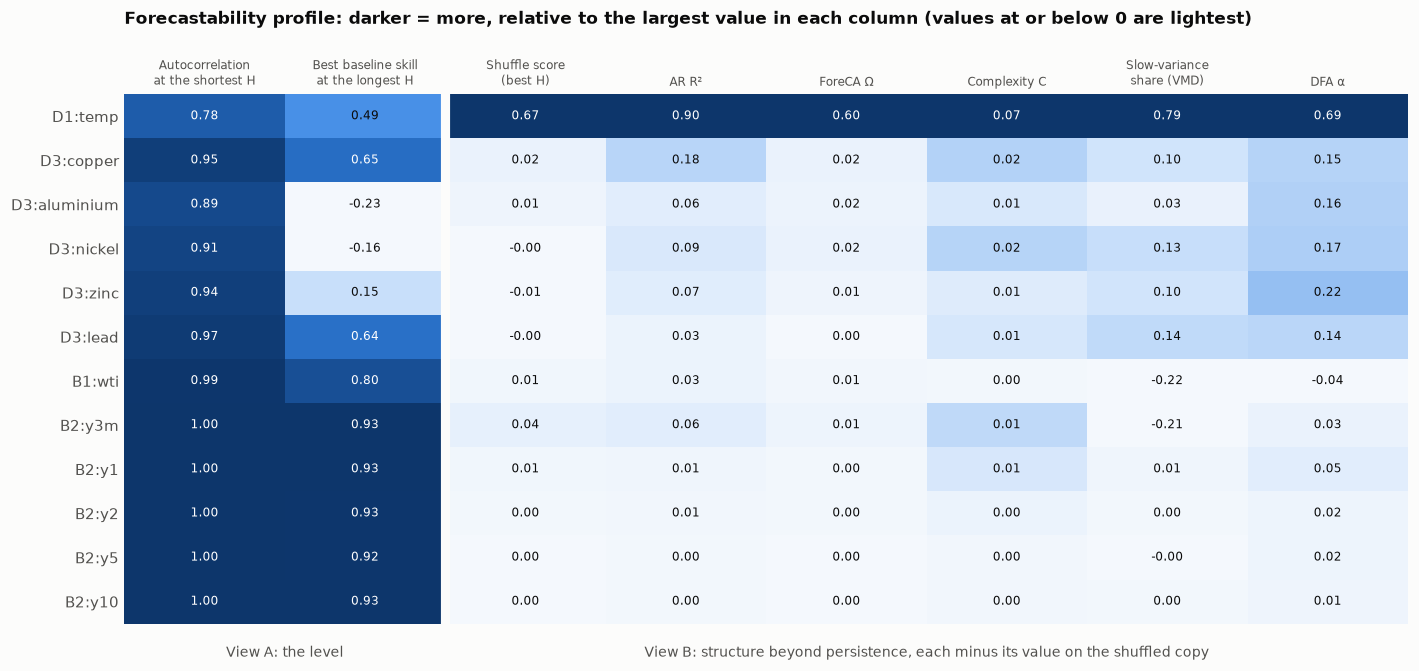

In [19]:
names = list(by_h["series"].unique())
shortest = by_h.loc[by_h.groupby("series")["H"].idxmin()].set_index("series")
longest = by_h.loc[by_h.groupby("series")["H"].idxmax()].set_index("series")
profile = pd.DataFrame({
    "Autocorrelation\nat the shortest H": shortest["acf_H"],
    "Best baseline skill\nat the longest H": longest[["nse_naive", "nse_seasonal_naive"]].max(axis=1),
    "Shuffle score\n(best H)": by_h.groupby("series")["eta_structure"].max(),
    "AR R²": structure["ar_r2"] - structure["ar_r2_shuffled"],
    "ForeCA Ω": entropy["foreca_omega"] - entropy_noise["foreca_omega"],
    "Complexity C": entropy["js_C"] - entropy_noise["js_C"],
    "Slow-variance\nshare (VMD)": decomposition["vmd_low_share"] - decomposition["vmd_low_share_shuffled"],
    "DFA α": memory["dfa_alpha"] - memory["dfa_alpha_shuffled"],
}).loc[names]
shade = (profile / profile.max()).clip(0, 1)               # share of the column's largest value; below 0 shown as 0
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.imshow(shade.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        ax.text(j, i, f"{profile.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if shade.iat[i, j] > 0.6 else INK)
ax.axvline(1.5, color=SURFACE, lw=6)                       # gap between view A and view B
ax.set_xticks(range(profile.shape[1]), profile.columns, fontsize=8)
ax.set_yticks(range(len(names)), names)
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.text(0.5, 12.0, "View A: the level", ha="center", va="top", fontsize=9, color=INK_2)
ax.text(4.5, 12.0, "View B: structure beyond persistence, each minus its value on the shuffled copy",
        ha="center", va="top", fontsize=9, color=INK_2)
ax.set_title("Forecastability profile: darker = more, relative to the largest value in each column "
             "(values at or below 0 are lightest)", loc="left", pad=46)
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "fig_ch03_03_forecastability_profile.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
AVERAGED = {"D3"}                       # World Bank monthly averages of daily prices (Section 3b)
hi = averaging["95 %"] + pd.Series({"acf1": 0, "ar_r2": 0, "foreca_omega": 0, "dfa_alpha": 0.03})
# DFA on 534 points varies by about 0.03 between shuffles, so alpha must clear the averaging range by that much


def vr_reading(g):
    sig = g[g["vr_p"] <= 0.05]
    if sig.empty:
        return "a random walk is not rejected at any horizon"
    parts = []
    for label, part in [("mean reversion (VR < 1)", sig[sig["vr"] < 1]), ("momentum (VR > 1)", sig[sig["vr"] > 1])]:
        if len(part):
            parts.append(f"{label} at H = {', '.join(map(str, part['H']))}")
    return " and ".join(parts)


stories = []
for name in names:
    d, g = name.split(":")[0], by_h[by_h["series"] == name]
    s, l, eta = shortest.loc[name], longest.loc[name], g["eta_structure"].max()
    averaged = d in AVERAGED
    persist = "strongly" if s["acf_H"] >= 0.9 else "moderately" if s["acf_H"] >= 0.5 else "weakly"
    baseline = "seasonal naive" if l["nse_seasonal_naive"] > l["nse_naive"] + 0.05 else "naive"
    beyond = "clear" if eta >= 0.10 else "slight" if eta >= 0.02 else "no"
    found, watch = [], []
    if profile.loc[name, "ForeCA Ω"] >= 0.2:
        found.append(f"a dominant cycle (Omega {entropy.loc[name, 'foreca_omega']:.2f}; "
                     f"VMD centre period {decomposition.loc[name, 'vmd_periods'].split(',')[0]} steps)")
    ar, ar_noise = structure.loc[name, "ar_r2"], structure.loc[name, "ar_r2_shuffled"]
    alpha, z = memory.loc[name, "dfa_alpha"], structure_view(d, name.split(":")[1])[0]
    if averaged and ar > hi["ar_r2"]:
        found.append(f"one-step dependence beyond what averaging creates (AR R2 {ar:.2f}; averaging alone "
                     f"up to {hi['ar_r2']:.2f})")
    elif not averaged and ar - ar_noise >= 0.05:
        found.append(f"one-step linear dependence (AR R2 {ar:.2f})")
    if averaged and alpha > hi["dfa_alpha"]:
        found.append(f"DFA alpha {alpha:.2f}, clearly above what averaging creates (up to "
                     f"{averaging.loc['dfa_alpha', '95 %']:.2f}): possibly longer memory")
    elif not averaged and alpha <= 1 and alpha - memory.loc[name, "dfa_alpha_shuffled"] >= 0.15:
        found.append(f"long memory (DFA alpha {alpha:.2f})")
    if averaged:
        labels = {"acf1": "lag-1 autocorrelation", "ar_r2": "AR R2", "dfa_alpha": "DFA alpha"}
        inside = [labels[k] for k in labels
                  if (structure.loc[name, k] if k in structure else memory.loc[name, k]) <= hi[k]]
        if inside:
            watch.append(f"{', '.join(inside)} no larger than monthly averaging alone creates")
    if (z == 0).mean() >= 0.2:
        watch.append(f"{(z == 0).mean():.0%} of the changes are exactly zero (values stuck at one level)")
    if entropy.loc[name, "sample_entropy"] < 0.8 * entropy_noise.loc[name, "sample_entropy"] and eta < 0.05:
        watch.append("sample entropy below its shuffled value without order in the changes: calm and turbulent "
                     "spells (Section 4b), which matter for forecast intervals, not point forecasts")
    if alpha > 1:
        watch.append(f"DFA alpha {alpha:.2f} above 1: a cycle or trend is left in the input")
    if memory.loc[name, "lyapunov"] > 0 and memory.loc[name, "lyapunov"] - memory.loc[name, "lyapunov_shuffled"] > 0.005:
        watch.append("Lyapunov exponent above its shuffled value: check for regime switches before reading chaos")
    if beyond == "clear":
        expect = f"room to beat the {baseline} forecast clearly"
    elif beyond == "slight":
        expect = "small gains over the naive forecast at the shortest horizons at most"
    else:
        expect = "matching the naive forecast is about the best possible; a large win needs checking for leakage"
    stories.append({"series": name, "level persists": persist, "baseline at the longest H": baseline,
                    "variance ratio": vr_reading(g), "order beyond persistence": beyond,
                    "structure found": "; ".join(found) or "none beyond noise",
                    "watch out": "; ".join(watch) or "-", "expectation": expect})
stories = pd.DataFrame(stories).set_index("series")
stories.to_csv(RESULTS / "tables" / "table_forecastability_profile.csv")
for name, r in stories.iterrows():
    print(f"{name}: the level persists {r['level persists']}; baseline at the longest H: {r['baseline at the longest H']}; "
          f"{r['variance ratio']}; {r['order beyond persistence']} order beyond persistence; "
          f"structure: {r['structure found']}; watch out: {r['watch out']}.\n    -> Expectation: {r['expectation']}.")

D1:temp: the level persists moderately; baseline at the longest H: seasonal naive; mean reversion (VR < 1) at H = 7, 14, 30, 60, 90; clear order beyond persistence; structure: a dominant cycle (Omega 0.60; VMD centre period 351 steps); one-step linear dependence (AR R2 0.90); watch out: DFA alpha 1.19 above 1: a cycle or trend is left in the input.
    -> Expectation: room to beat the seasonal naive forecast clearly.
D3:copper: the level persists strongly; baseline at the longest H: naive; momentum (VR > 1) at H = 3, 6, 9; slight order beyond persistence; structure: one-step dependence beyond what averaging creates (AR R2 0.18; averaging alone up to 0.11); watch out: DFA alpha no larger than monthly averaging alone creates.
    -> Expectation: small gains over the naive forecast at the shortest horizons at most.
D3:aluminium: the level persists moderately; baseline at the longest H: naive; a random walk is not rejected at any horizon; no order beyond persistence; structure: none beyond

**What this tells us.** The profile shows the two views pulling apart. In view A almost every row is dark: the
levels of the yields, WTI and most metals barely move, and the naive forecast still explains 80 to 93 % of the
variance of WTI and the yields at the longest horizon. In view B only temperature's row is dark. It is the one
series with order beyond persistence (shuffle score 0.67), a dominant annual cycle (Ω 0.60 above noise, VMD period
351 days), slow components (0.79 more slow variance than noise) and complexity above noise.

The sentences group the twelve series into four stories.

- **Temperature: stationary, seasonal, structured.** The level forgets quickly (autocorrelation 0.78 at 7 days,
  0.03 at 90), it reverts to its seasonal mean at every horizon, and the seasonal naive forecast is the baseline at
  the longest horizon. Every structure measure agrees, so this is where models should beat the baselines clearly.
  The one warning sign, DFA above 1, is the cycle itself.
- **Copper: a near random walk with a little extra.** Its changes carry more one-month structure than averaging
  creates (AR R² 0.18 against at most 0.11), and its variance ratios (1.47 to 1.63 up to 9 months) are a little
  above the 1.33 to 1.44 that averaging alone gives. The shuffle score is still only 0.025 at 3 months, so expect
  small gains at the shortest horizon at most.
- **Aluminium, nickel, zinc and lead: averaged random walks.** They show no structure that monthly averaging does
  not create, apart from zinc's slightly high DFA exponent, and their variance ratios above 1 at short horizons
  are the same averaging effect. Matching the naive forecast is about the best a model can do.
- **WTI and the yields: random walks with calm and turbulent spells.** There is no order in the changes, but
  sample entropy is below noise because of volatility clustering (Section 4b). The 1- and 2-year yields add
  momentum between 2 weeks and 3 months, and the 3-month yield adds a zero-lower-bound regime (24 % of its changes
  are exactly zero) that also explains its Lyapunov exponent. The structure is in the size of the changes, so it
  matters for forecast intervals, not for the level.

Each series now has an expectation in plain words, and each rests on at least two measures built on different
ideas. The forecasting notebooks check these expectations model by model.

### Which measures to use for which data

The twelve series here cover four kinds of data. Beyond this chapter the same panel applies, but which measures
should lead depends on the data:

| Your data | Start with | Read with care | Why |
|---|---|---|---|
| Sales, demand or counts with many zeros | ADI–CV² classes, naive and seasonal-naive skill | sample and permutation entropy | zeros are repeated values: they lower entropy without adding forecastability |
| Prices, rates, anything with a unit root | variance ratio, shuffle score and AR $R^2$ on the changes | every entropy, DFA and decomposition share on the level; sample entropy of the changes | on a trending level they report persistence as structure; calm spells look regular (Section 4b) |
| Strong seasonality (temperature, energy load, traffic) | seasonal-naive skill, $\Omega$ and VMD periods | DFA on the raw series | the cycle lifts $\alpha$ above 1; remove it first |
| Short series (a few hundred points) | autocorrelation, naive skill, variance ratio, AR $R^2$ | multiscale entropy, Lyapunov, DFA, spectral entropy | estimates are noisy; compare with a shuffled copy |
| Aggregated or averaged data (monthly averages) | the same measures plus a simulation of the aggregation | one-step correlation and AR $R^2$ | averaging alone creates one-step correlation (Section 3b) |
| Low-noise physical systems | complexity–entropy plane, Lyapunov horizon | | designed for deterministic dynamics; here they are informative |
| Choosing a context length for a foundation model | autocorrelation decay, DFA, VMD centre periods | | they say how far back the past still matters |

## 8 · The forecastability table and the expected difficulty

The table has one row per series with every measure, including the shuffled-copy references
(`results/tables/table_forecastability.csv`). From it we write down two rankings **before** any zero-shot model
runs, one for each of two questions:

- **How hard is the level to forecast at long horizons?** The average rank, across series, of the naive and
  seasonal-naive skill and the autocorrelation at the longest horizon (higher = easier).
- **How much room is there for a model to beat the naive forecast?** The average rank of the shuffle score on the
  stationary form, the AR variance explained and $\Omega$ (higher = more room).

Later in the chapter, the zero-shot results are checked against these expectations.

In [21]:
longest = by_h.loc[by_h.groupby("series")["H"].idxmax()].set_index("series")
table = (variability.join(structure).join(entropy).join(entropy_noise.add_suffix("_shuffled"))
         .join(decomposition).join(memory)
         .join(longest[["H", "acf_H", "nse_naive", "nse_seasonal_naive", "vr", "vr_p", "eta_level"]].add_suffix("_longestH")))
table["eta_structure_best"] = by_h.groupby("series")["eta_structure"].max()
table["best_baseline_nse_longestH"] = table[["nse_naive_longestH", "nse_seasonal_naive_longestH"]].max(axis=1)
table["level_ease_rank"] = difficulty_rank(table, ["best_baseline_nse_longestH", "acf_H_longestH"])
table["room_beyond_naive_rank"] = difficulty_rank(table, ["eta_structure_best", "ar_r2", "foreca_omega"])
(RESULTS / "tables").mkdir(parents=True, exist_ok=True)
table.to_csv(RESULTS / "tables" / "table_forecastability.csv")
table[["view", "best_baseline_nse_longestH", "acf_H_longestH", "eta_structure_best", "ar_r2", "foreca_omega",
       "level_ease_rank", "room_beyond_naive_rank"]].sort_values("room_beyond_naive_rank").round(3)

,view,best_baseline_nse_longestH,acf_H_longestH,eta_structure_best,ar_r2,foreca_omega,level_ease_rank,room_beyond_naive_rank
series,,,,,,,,
D1:temp,level,0.492,0.027,0.673,0.898,0.602,10,1
D3:copper,log change,0.650,0.708,0.025,0.184,0.097,7,2
D3:aluminium,log change,-0.225,0.307,0.014,0.061,0.082,12,3
B2:y3m,change,0.932,0.961,0.037,0.062,0.018,1,3
D3:nickel,log change,-0.158,0.420,-0.004,0.107,0.094,10,5
D3:zinc,log change,0.147,0.518,-0.006,0.065,0.079,9,6
B1:wti,change,0.797,0.886,0.008,0.030,0.009,6,6
B2:y1,change,0.931,0.961,0.009,0.014,0.007,2,8
D3:lead,log change,0.636,0.787,-0.002,0.029,0.078,7,9


In [22]:
room = table.sort_values("room_beyond_naive_rank")
print("Expected room for a model to beat the naive forecast, most to least:")
for i, (name, r) in enumerate(room.iterrows(), 1):
    print(f"  {i:2d}. {name:14s} shuffle score {r['eta_structure_best']:.2f}, AR R2 {r['ar_r2']:.2f}, Omega {r['foreca_omega']:.2f}")
rw = table.index[(table["vr_p_longestH"] > 0.05) & (table["eta_structure_best"] < 0.05)].tolist()
print(f"Near random walks (VR = 1 not rejected at the longest H and almost no order in the changes): {', '.join(rw) or 'none'}")

Expected room for a model to beat the naive forecast, most to least:
   1. D1:temp        shuffle score 0.67, AR R2 0.90, Omega 0.60
   2. D3:copper      shuffle score 0.02, AR R2 0.18, Omega 0.10
   3. D3:aluminium   shuffle score 0.01, AR R2 0.06, Omega 0.08
   4. B2:y3m         shuffle score 0.04, AR R2 0.06, Omega 0.02
   5. D3:nickel      shuffle score -0.00, AR R2 0.11, Omega 0.09
   6. D3:zinc        shuffle score -0.01, AR R2 0.07, Omega 0.08
   7. B1:wti         shuffle score 0.01, AR R2 0.03, Omega 0.01
   8. B2:y1          shuffle score 0.01, AR R2 0.01, Omega 0.01
   9. D3:lead        shuffle score -0.00, AR R2 0.03, Omega 0.08
  10. B2:y2          shuffle score 0.00, AR R2 0.01, Omega 0.01
  11. B2:y10         shuffle score 0.00, AR R2 0.00, Omega 0.00
  12. B2:y5          shuffle score 0.00, AR R2 0.00, Omega 0.00
Near random walks (VR = 1 not rejected at the longest H and almost no order in the changes): D3:copper, D3:aluminium, D3:nickel, D3:zinc, D3:lead, B1:wti, B2:y5

**What this tells us.** Temperature is first by a wide margin. Copper is second but far behind (shuffle score
0.02, AR R² 0.18), followed by aluminium and the 3-month yield, then the other metals and WTI, with the longer
yields at the bottom. Eight of the twelve series qualify as near random walks: all five metals, WTI, and the 5- and
10-year yields. Copper's AR R² of 0.18 is more than monthly averaging alone creates (at most 0.11), but it is
one-step structure: the shuffle score is 0.025 at 3 months and below zero by 12 months. The other ranking, how easy
the level is at the longest horizon, runs the other way: the yields and WTI are easy because they barely move,
while temperature is among the hardest because its level swings with the seasons.

The zero-shot results later in the chapter are read against this ranking. Clear wins over the naive forecast
should appear on temperature. On the metals, WTI and the yields, a model that matches the naive forecast is doing
about as well as the data allow.

**What this means for the zero-shot study.**

- On series near the bottom of the "room" ranking, the naive forecast is close to the best achievable. A
  foundation model that matches it is doing well, and one that beats it by a wide margin deserves suspicion
  (leakage, test data seen in pre-training, or luck).
- On series near the top, there is structure to exploit. This is where the chapter expects foundation models,
  with their long contexts and learned patterns, to pull away from simple baselines.
- The evaluation notebooks report results by these groups, so a model's average score cannot hide where it gains
  and where it does not.

## Key takeaways

- Forecastability is a property of the series, the horizon and the information used, not of a model. Measuring it
  first gives every later error a reference and names the baseline each model must beat.
- Forecastability has two faces. A persistent level is easy to forecast, but that does not mean a model can add
  anything beyond "no change".
- The horizon chart shows how quickly each series forgets its past; the shuffle score on the stationary form shows
  how much order is left for a model to use.
- Every structure measure needs a reference. The same values in random order show what the number looks like
  without structure, and a simulation shows what a known artefact (monthly averaging) produces.
- Entropy measures need a stationary input: on trending levels they report structure that is only persistence.
- The Lyapunov horizon is shown with its shuffled baseline, because on noisy data the method finds "chaos" in
  noise.
- No single measure decides. Read them as a chain: does the level persist, is persistence all there is, what kind
  of structure is left, could it be an artefact? Agreement between measures built on different ideas is what makes
  a conclusion solid.
- The expected-difficulty ranking is written before any model runs, so it can be tested rather than fitted.

## References

The selection of measures follows the forecastability chapter of this textbook:

- Manokhin, V. (2026). *Mastering Modern Time Series Forecasting: A Comprehensive Guide to Statistical, Machine Learning, and Deep Learning Models in Python*. North Star Academic Press, ISBN 978-1-9194658-3-8. Chapter 2, "The Forecastability of Time Series: Understanding the Limits". [Book page](https://leanpub.com/mastering_modern_time_series_forecasting)

Sources for each idea and measure, in the order they appear:

- Forecastability as variance explained, equation (0), and the AR measure, equation (4): Granger, C. W. J., & Newbold, P. (1986). *Forecasting Economic Time Series* (2nd ed.). Academic Press. [doi:10.1016/C2009-0-21183-8](https://doi.org/10.1016/C2009-0-21183-8)
- The naive forecast as the benchmark for a random walk: Hewamalage, H., Ackermann, K., & Bergmeir, C. (2023). Forecast evaluation for data scientists: common pitfalls and best practices. *Data Mining and Knowledge Discovery*, 37(2), 788–832. [doi:10.1007/s10618-022-00894-5](https://doi.org/10.1007/s10618-022-00894-5)
- Scaled errors and MASE: Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679–688. [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)
- Test data seen in pre-training: Aksu, T., Woo, G., Liu, J., Liu, X., Liu, C., Savarese, S., Xiong, C., & Sahoo, D. (2024). GIFT-Eval: a benchmark for general time series forecasting model evaluation. Preprint, [arXiv:2410.10393](https://arxiv.org/abs/2410.10393)
- What can be forecast: Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), Section 1.1, What can be forecast? OTexts. [otexts.com/fpp3](https://otexts.com/fpp3/what-can-be-forecast.html)
- ADI–CV² demand classes (Section 1): Syntetos, A. A., Boylan, J. E., & Croston, J. D. (2005). On the categorization of demand patterns. *Journal of the Operational Research Society*, 56(5), 495–503. [doi:10.1057/palgrave.jors.2601841](https://doi.org/10.1057/palgrave.jors.2601841)
- Nash–Sutcliffe efficiency (Section 2): Nash, J. E., & Sutcliffe, J. V. (1970). River flow forecasting through conceptual models part I: a discussion of principles. *Journal of Hydrology*, 10(3), 282–290. [doi:10.1016/0022-1694(70)90255-6](https://doi.org/10.1016/0022-1694(70)90255-6)
- Variance ratio and its robust test (Section 2): Lo, A. W., & MacKinlay, A. C. (1988). Stock market prices do not follow random walks: evidence from a simple specification test. *The Review of Financial Studies*, 1(1), 41–66. [doi:10.1093/rfs/1.1.41](https://doi.org/10.1093/rfs/1.1.41)
- Shuffle score (Section 2): Kaboudan, M. A. (1999). A measure of time series' predictability using genetic programming applied to stock returns. *Journal of Forecasting*, 18(5), 345–357. [doi:10.1002/(SICI)1099-131X(199909)18:5<345::AID-FOR744>3.0.CO;2-7](https://doi.org/10.1002/(SICI)1099-131X(199909)18:5%3C345::AID-FOR744%3E3.0.CO;2-7)
- Averaging and the autocorrelation of changes, equation (4b) (Section 3b): Working, H. (1960). Note on the correlation of first differences of averages in a random chain. *Econometrica*, 28(4), 916–918. [doi:10.2307/1907574](https://doi.org/10.2307/1907574)
- Spectral entropy and $\Omega$ (Section 4): Goerg, G. M. (2013). Forecastable component analysis. *Proceedings of the 30th International Conference on Machine Learning*, PMLR 28(2), 64–72. [proceedings.mlr.press](https://proceedings.mlr.press/v28/goerg13.html)
- Permutation entropy (Section 4): Bandt, C., & Pompe, B. (2002). Permutation entropy: a natural complexity measure for time series. *Physical Review Letters*, 88(17), 174102. [doi:10.1103/PhysRevLett.88.174102](https://doi.org/10.1103/PhysRevLett.88.174102)
- Sample entropy (Section 4): Richman, J. S., & Moorman, J. R. (2000). Physiological time-series analysis using approximate entropy and sample entropy. *American Journal of Physiology: Heart and Circulatory Physiology*, 278(6), H2039–H2049. [doi:10.1152/ajpheart.2000.278.6.H2039](https://doi.org/10.1152/ajpheart.2000.278.6.H2039)
- Multiscale entropy (Section 4): Costa, M., Goldberger, A. L., & Peng, C.-K. (2002). Multiscale entropy analysis of complex physiologic time series. *Physical Review Letters*, 89(6), 068102. [doi:10.1103/PhysRevLett.89.068102](https://doi.org/10.1103/PhysRevLett.89.068102)
- SVD entropy (Section 4): Roberts, S. J., Penny, W., & Rezek, I. (1999). Temporal and spatial complexity measures for electroencephalogram based brain-computer interfacing. *Medical & Biological Engineering & Computing*, 37(1), 93–98. [doi:10.1007/BF02513272](https://doi.org/10.1007/BF02513272)
- Complexity–entropy plane (Section 4): Rosso, O. A., Larrondo, H. A., Martin, M. T., Plastino, A., & Fuentes, M. A. (2007). Distinguishing noise from chaos. *Physical Review Letters*, 99(15), 154102. [doi:10.1103/PhysRevLett.99.154102](https://doi.org/10.1103/PhysRevLett.99.154102)
- Empirical mode decomposition (Section 5): Huang, N. E., Shen, Z., Long, S. R., Wu, M. C., Shih, H. H., Zheng, Q., Yen, N.-C., Tung, C. C., & Liu, H. H. (1998). The empirical mode decomposition and the Hilbert spectrum for nonlinear and non-stationary time series analysis. *Proceedings of the Royal Society A*, 454(1971), 903–995. [doi:10.1098/rspa.1998.0193](https://doi.org/10.1098/rspa.1998.0193)
- Variational mode decomposition (Section 5): Dragomiretskiy, K., & Zosso, D. (2014). Variational mode decomposition. *IEEE Transactions on Signal Processing*, 62(3), 531–544. [doi:10.1109/TSP.2013.2288675](https://doi.org/10.1109/TSP.2013.2288675)
- Detrended fluctuation analysis (Section 6): Peng, C.-K., Buldyrev, S. V., Havlin, S., Simons, M., Stanley, H. E., & Goldberger, A. L. (1994). Mosaic organization of DNA nucleotides. *Physical Review E*, 49(2), 1685–1689. [doi:10.1103/PhysRevE.49.1685](https://doi.org/10.1103/PhysRevE.49.1685)
- Largest Lyapunov exponent (Section 6): Rosenstein, M. T., Collins, J. J., & De Luca, C. J. (1993). A practical method for calculating largest Lyapunov exponents from small data sets. *Physica D*, 65(1–2), 117–134. [doi:10.1016/0167-2789(93)90009-P](https://doi.org/10.1016/0167-2789(93)90009-P)